# Task 23 — Training & Deploying TensorFlow Models at Scale


---

## Overview

**Scope of this notebook: the 28/10 slot of the timeline — Phases 1–8 (up to clusters and the tuning analog).** The capstone (29/10) and capstone plans, exercises and demo (30/10) come next.

Tasks 16–22 were about *building and training* models. Task 23 is about everything that happens **around** the model once it works:

| Part | Phases | Question it answers |
|---|---|---|
| **Serving** | 1 → 4 | How do other systems call my model reliably, update it without downtime, and scale it? |
| **Edge deployment** | 5 | How do I shrink a model for phones, microcontrollers and browsers? |
| **Training speed** | 6 → 7 | How do I use GPUs well and train one model across many devices? |
| **At scale** | 8 | How do clusters, cloud training jobs and tuning services work? |

**How this notebook is built so it runs top to bottom on any machine**

| If you have… | What happens |
|---|---|
| Internet | Real MNIST is downloaded. Without it, *learnable synthetic* stand-ins are generated so every cell still runs (accuracy numbers will differ). |
| Docker Desktop running + `tensorflow/serving` pulled | Phases 2 and 3 start real TF Serving containers from Python and query them over REST and gRPC. Without Docker those cells print *SKIPPED* and keep going. |
| An NVIDIA GPU (Linux / WSL2 / Colab) | The GPU is split into 2 virtual GPUs for the multi-device experiments. Without one, the CPU is split into 4 *logical* CPU devices, which is enough to run every Distribution Strategy for real (speed-ups will be small — that is explained where it matters). |
| A cloud account | Phase 4 and the cloud parts of Phase 8 are written as a **design document** with ready-to-run code behind a `RUN_CLOUD = False` switch. |

All generated files go into `task23_work/` next to this notebook. Nothing secret is written anywhere.

## 0. Setup

**Important:** device configuration (virtual GPUs / logical CPUs) can only be set **before** TensorFlow touches a device, so this cell must run first after every kernel restart.

> **Windows note:** native Windows TensorFlow has been CPU-only since TF 2.11. For a GPU on Windows use WSL2 or Google Colab. Everything here still runs on CPU.

In [1]:
import os, sys, json, time, shutil, socket, subprocess, threading, textwrap, random, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide INFO/WARNING spam from the C++ runtime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import absl.logging
tf.get_logger().setLevel("ERROR"); absl.logging.set_verbosity(absl.logging.ERROR)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Device setup (must happen before any op runs) -------------------------
physical_gpus = tf.config.list_physical_devices("GPU")
if physical_gpus:
    # Phase 6: split GPU 0 into two 2 GiB virtual GPUs so multi-device code can be tested on one card
    tf.config.set_logical_device_configuration(
        physical_gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=2048),
         tf.config.LogicalDeviceConfiguration(memory_limit=2048)])
    DEVICES = [d.name for d in tf.config.list_logical_devices("GPU")]
else:
    # No GPU: split the CPU into 4 logical devices -> MirroredStrategy etc. still run for real
    cpu = tf.config.list_physical_devices("CPU")[0]
    tf.config.set_logical_device_configuration(cpu, [tf.config.LogicalDeviceConfiguration()] * 4)
    DEVICES = [d.name for d in tf.config.list_logical_devices("CPU")]

HAS_GPU = bool(physical_gpus)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| Python:", sys.version.split()[0])
print("Physical GPUs:", physical_gpus)
print("Logical compute devices used in this notebook:", DEVICES)

WORK = Path("task23_work").resolve(); WORK.mkdir(exist_ok=True)
SERVE_DIR = WORK / "serving"; SERVE_DIR.mkdir(exist_ok=True)   # mounted into TF Serving as /models
SCRIPTS = WORK / "scripts"; SCRIPTS.mkdir(exist_ok=True)
print("Work dir:", WORK)

TensorFlow: 2.22.0-rc0 | Keras: 3.16.0.dev2026102803 | Python: 3.14.6
Physical GPUs: []
Logical compute devices used in this notebook: ['/device:CPU:0', '/device:CPU:1', '/device:CPU:2', '/device:CPU:3']
Work dir: C:\Users\HP\Documents\Task23\task23_work


In [2]:
# ---- Small utilities reused everywhere ------------------------------------
def benchmark(fn, warmup=2, repeats=5):
    '''Task 18 discipline: warm-up calls excluded, >=5 timed repeats, return (mean, std) in seconds.'''
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return float(np.mean(times)), float(np.std(times))

def fmt_ms(mean_std):
    m, s = mean_std
    return f"{m*1000:.2f} ± {s*1000:.2f} ms"

def run_py(script_path, args=(), env_extra=None, timeout=900):
    '''Run a helper script in a fresh Python process (needed whenever TF must be configured differently).'''
    env = os.environ.copy(); env.update(env_extra or {})
    r = subprocess.run([sys.executable, str(script_path), *map(str, args)], capture_output=True,
                       text=True, env=env, timeout=timeout)
    return r.returncode, r.stdout, r.stderr

def tail(text, n=15):
    lines = [l for l in text.splitlines() if l.strip() and "absl::InitializeLog" not in l]
    return "\n".join(lines[-n:])

def dir_size_mb(path):
    p = Path(path)
    if p.is_file():
        return p.stat().st_size / 1e6
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6

def tree(path, prefix=""):
    '''Print a directory tree with file sizes (for the SavedModel anatomy).'''
    path = Path(path)
    entries = sorted(path.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, e in enumerate(entries):
        last = i == len(entries) - 1
        size = f"  ({e.stat().st_size/1024:.1f} KB)" if e.is_file() else "/"
        print(prefix + ("└── " if last else "├── ") + e.name + size)
        if e.is_dir():
            tree(e, prefix + ("    " if last else "│   "))

### 0.1 Data — MNIST (primary serving example)

Real MNIST if the download works; otherwise a synthetic, *learnable* MNIST look-alike (each class = strokes partly shared with other classes + random shifts, distractor strokes and noise; a plain MLP reaches ~92 %, so it is not trivially separable), so all downstream code paths behave the same.

real MNIST | train (20000, 28, 28) | valid (5000, 28, 28) | test (10000, 28, 28)


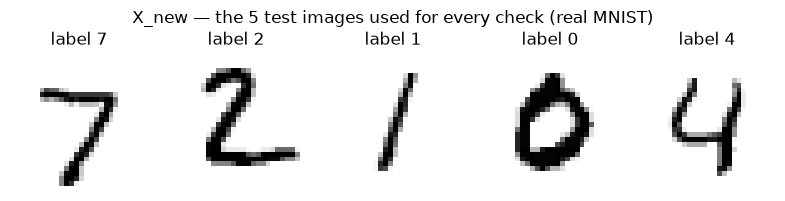

In [3]:
def make_synthetic_mnist(n_train=60000, n_test=10000, seed=0):
    rng = np.random.default_rng(seed)
    def stroke(img, r0, c0, r1, c1):
        for t in np.linspace(0, 1, 40):
            r, cc = int(r0 + t*(r1-r0)), int(c0 + t*(c1-c0))
            img[max(r-1,0):r+2, max(cc-1,0):cc+2] = 1.0
    pool = [rng.integers(4, 24, 4) for _ in range(8)]           # strokes shared between classes
    templates = np.zeros((10, 28, 28), np.float32)
    for c in range(10):
        for k in rng.choice(8, 3, replace=False): stroke(templates[c], *pool[k])
        stroke(templates[c], *rng.integers(4, 24, 4))           # one class-specific stroke
    def sample(n):
        y = rng.integers(0, 10, n); X = templates[y].copy()
        for i in range(n):
            X[i] = np.roll(X[i], rng.integers(-3, 4, 2), axis=(0, 1))
            if rng.random() < 0.5:                               # random distractor stroke
                stroke(X[i], *rng.integers(2, 26, 4))
        X = np.clip(X * rng.uniform(0.5, 1.0, (n, 1, 1)) + rng.normal(0, 0.35, X.shape), 0, 1)
        return (X * 255).astype(np.uint8), y.astype(np.uint8)
    return sample(n_train), sample(n_test)

try:
    (X_train_full, y_train_full), (X_test_raw, y_test) = keras.datasets.mnist.load_data()
    DATA_SOURCE = "real MNIST"
except Exception as e:
    print("MNIST download failed ->", type(e).__name__, "- using synthetic MNIST stand-in")
    (X_train_full, y_train_full), (X_test_raw, y_test) = make_synthetic_mnist()
    DATA_SOURCE = "synthetic MNIST stand-in"

# A 20k-image training subset keeps every phase fast on a laptop CPU
X_train_raw, y_train = X_train_full[:20000], y_train_full[:20000]
X_valid_raw, y_valid = X_train_full[55000:], y_train_full[55000:]
X_train = X_train_raw.astype("float32") / 255.0
X_valid = X_valid_raw.astype("float32") / 255.0
X_test  = X_test_raw.astype("float32") / 255.0
X_new   = X_test[:5]                         # the 5 "new" images used for every self-test

# Saved to disk so the helper scripts (multi-worker, tuning trials) can load the same data
np.savez_compressed(WORK / "mnist_subset.npz", X_train=X_train, y_train=y_train,
                    X_valid=X_valid, y_valid=y_valid)
print(DATA_SOURCE, "| train", X_train.shape, "| valid", X_valid.shape, "| test", X_test.shape)

fig, axes = plt.subplots(1, 5, figsize=(8, 2))
for ax, img, lab in zip(axes, X_new, y_test[:5]):
    ax.imshow(img, cmap="binary"); ax.set_title(f"label {lab}"); ax.axis("off")
plt.suptitle(f"X_new — the 5 test images used for every check ({DATA_SOURCE})"); plt.tight_layout(); plt.show()

---
# Phase 1 — Exporting & Inspecting SavedModels

### 1.1 Why a dedicated prediction service? (Task 1)

Once a model works, the rest of the infrastructure needs to call it on live data. Wrapping it in its own service:

* **Decouples** the model from the application — the app only knows an endpoint and a request format.
* Lets you **switch model versions** or **scale** the model service independently of the app (more replicas of the model, not of the whole app).
* Enables **A/B experiments** and **canary releases** between versions.
* Guarantees **every component uses the same model version** (no "the web tier is on v3, the batch job still on v2").
* **Simplifies testing** — the model can be tested in isolation, and the app can be tested against a stub.

**Why not just write a Flask app?** You could, and for a toy it is fine. But you would end up re-implementing what TF Serving already does in optimised C++: versioned hot-reload with graceful hand-over, automatic request batching, gRPC + REST, multi-model serving, model warm-up, and high throughput without the Python GIL. That is a lot of subtle, failure-prone code to own.

In [4]:
def build_mnist_model(hidden=(100,), name="mnist_v1"):
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(28, 28), name="flatten_input"))
    model.add(keras.layers.Flatten())
    for i, units in enumerate(hidden):
        model.add(keras.layers.Dense(units, activation="relu"))
    model.add(keras.layers.Dense(10, activation="softmax"))
    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer=keras.optimizers.SGD(learning_rate=0.05, momentum=0.9),
                  metrics=["accuracy"])
    return model

tf.random.set_seed(SEED)
model_v1 = build_mnist_model()
hist = model_v1.fit(X_train, y_train, epochs=3, batch_size=64,
                    validation_data=(X_valid, y_valid), verbose=2)
v1_test_acc = model_v1.evaluate(X_test, y_test, verbose=0)[1]
print(f"\nModel v1 test accuracy: {v1_test_acc:.4f}")

Epoch 1/3


313/313 - 4s - 11ms/step - accuracy: 0.8868 - loss: 0.3936 - val_accuracy: 0.9536 - val_loss: 0.1612


Epoch 2/3


313/313 - 2s - 6ms/step - accuracy: 0.9521 - loss: 0.1665 - val_accuracy: 0.9624 - val_loss: 0.1237


Epoch 3/3


313/313 - 2s - 6ms/step - accuracy: 0.9675 - loss: 0.1126 - val_accuracy: 0.9702 - val_loss: 0.1035



Model v1 test accuracy: 0.9597


### 1.2 Export to a versioned directory (Task 2) + the reusable `export_model` helper (Task 10)

**Why is the version a directory name?** TF Serving watches the *model base path* (e.g. `my_mnist_model/`) and treats every numeric sub-directory as a version. Deploying v2 is "drop `0002/` next to `0001/`"; rolling back is "delete `0002/`". No config change, no restart — the file system *is* the deployment API. Zero-padding (`0001`) keeps them sorted in file browsers; TF Serving reads them as integers.

**Version note:** with Keras 3, `model.save()` writes the native `.keras` format, which TF Serving cannot read. `model.export(path)` writes a serving SavedModel. The helper below uses `export()` when available and falls back to `tf.saved_model.save()`.

In [5]:
def signature_io(path, signature="serving_default"):
    '''Return (input_name, output_name, input_spec) of a SavedModel signature.'''
    sig = tf.saved_model.load(str(path)).signatures[signature]
    in_name, in_spec = next(iter(sig.structured_input_signature[1].items()))
    out_name = next(iter(sig.structured_outputs.keys()))
    return in_name, out_name, in_spec

def export_model(model, name, version, X_check, base_dir=SERVE_DIR, atol=1e-5, verbose=True):
    '''Export `model` to base_dir/name/<version:04d>, reload it and assert predictions match.'''
    path = Path(base_dir) / name / f"{int(version):04d}"
    if path.exists():
        shutil.rmtree(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if hasattr(model, "export"):
        model.export(str(path), verbose=False)          # Keras 3 / tf.keras >= 2.13
    else:
        tf.saved_model.save(model, str(path))
    # ---- post-export self-test ----
    reloaded = tf.saved_model.load(str(path))
    sig = reloaded.signatures["serving_default"]
    in_name, in_spec = next(iter(sig.structured_input_signature[1].items()))
    x = tf.constant(X_check, dtype=in_spec.dtype)
    served = next(iter(sig(**{in_name: x}).values())).numpy()
    local = np.asarray(model(x, training=False))
    max_diff = float(np.max(np.abs(served - local)))
    assert np.allclose(served, local, atol=atol), f"Self-test FAILED for {path}: max diff {max_diff}"
    if verbose:
        print(f"Exported {path.relative_to(WORK)}  |  {dir_size_mb(path):.2f} MB  |  self-test OK (max diff {max_diff:.1e})")
    return path

model_name = "my_mnist_model"
v1_path = export_model(model_v1, model_name, 1, X_new)

Exported serving\my_mnist_model\0001  |  0.34 MB  |  self-test OK (max diff 1.9e-08)


### 1.3 Anatomy of the SavedModel (Task 3)

```
my_mnist_model/              <- model base path (what TF Serving watches)
└── 0001/                    <- one version = one directory
    ├── assets/              <- extra files the graph needs at run time: vocabularies, class names, lookup tables
    ├── fingerprint.pb       <- (TF >= 2.11) hashes that identify this exact SavedModel
    ├── saved_model.pb       <- the computation graph(s) + signatures, as a protocol buffer (Task 19)
    └── variables/
        ├── variables.data-00000-of-00001   <- the weight values (big models are sharded: -of-0000N)
        └── variables.index                 <- index: which variable lives where in the data shards
```

In [6]:
tree(v1_path)

├── assets/
├── variables/
│   ├── variables.data-00000-of-00001  (311.2 KB)
│   └── variables.index  (0.4 KB)
├── fingerprint.pb  (0.1 KB)
└── saved_model.pb  (23.8 KB)


### 1.4 Loading it back two ways (Task 4)

| Loader | Returns | How you call it |
|---|---|---|
| `tf.saved_model.load()` | a generic *trackable* object — **not** a Keras model | call a signature / function with tensors of the **right dtype** |
| Keras | Keras 2: `keras.models.load_model()` → full Keras model with `predict()`. **Keras 3** cannot load a SavedModel as a model; it wraps it as a layer with `keras.layers.TFSMLayer` | `model.predict()` / call the layer |

In [7]:
# Way 1: low-level TensorFlow loader
saved_model = tf.saved_model.load(str(v1_path))
print("type:", type(saved_model).__name__)
infer = saved_model.signatures["serving_default"]
y_pred_tf = next(iter(infer(tf.constant(X_new, dtype=tf.float32)).values())).numpy()

# Way 2: Keras loader (version dependent)
if hasattr(keras.layers, "TFSMLayer"):
    keras_view = keras.Sequential([keras.Input((28, 28)), keras.layers.TFSMLayer(str(v1_path), call_endpoint="serving_default")])
    out = keras_view.predict(X_new, verbose=0)
    y_pred_keras = next(iter(out.values())) if isinstance(out, dict) else out
    print("Keras 3 -> loaded through keras.layers.TFSMLayer")
else:
    y_pred_keras = keras.models.load_model(str(v1_path)).predict(X_new, verbose=0)
    print("Keras 2 -> keras.models.load_model")

print("Identical predictions:", np.allclose(y_pred_tf, y_pred_keras, atol=1e-6))
print("Predicted classes:", y_pred_tf.argmax(1), "| true:", y_test[:5])
print(np.round(y_pred_tf, 3))

type: _UserObject


Keras 3 -> loaded through keras.layers.TFSMLayer
Identical predictions: True
Predicted classes: [7 2 1 0 4] | true: [7 2 1 0 4]
[[0.    0.    0.    0.    0.    0.    0.    1.    0.    0.   ]
 [0.    0.    0.981 0.018 0.    0.    0.    0.    0.    0.   ]
 [0.    0.997 0.002 0.    0.    0.    0.    0.001 0.    0.   ]
 [1.    0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.998 0.    0.    0.    0.    0.002]]


### 1.5 Metagraphs, tags and signatures (Task 5)

* A **metagraph** = a computation graph + its function signatures (+ asset info). A SavedModel can hold several (e.g. one for serving on CPU, one on GPU).
* A metagraph is selected by its **tags** — a Keras export produces one metagraph tagged **`serve`**.
* A **signature definition** names a callable entry point: input names/dtypes/shapes → output names/dtypes/shapes.
  * `serving_default` — the model's forward pass; what TF Serving uses when you don't name a signature.
  * `__saved_model_init_op` — an internal initialisation function (restores variables, initialises lookup tables).

### 1.6 Inspect and test-run with `saved_model_cli` (Tasks 6–7)

In [8]:
SAVED_MODEL_CLI = [sys.executable, "-m", "tensorflow.python.tools.saved_model_cli"]   # works on Windows too
r = subprocess.run(SAVED_MODEL_CLI + ["show", "--dir", str(v1_path), "--all"], capture_output=True, text=True)
show_out = r.stdout
# print only the signature part (the rest lists internal concrete functions)
print(show_out.split("Concrete Functions")[0] if "Concrete Functions" in show_out else show_out[:3000])

in_name, out_name, in_spec = signature_io(v1_path)
print(f"==> input  name: {in_name!r}  dtype: {in_spec.dtype.name}  shape: {tuple(in_spec.shape)}")
print(f"==> output name: {out_name!r}  shape: (-1, 10)")


MetaGraphDef with tag-set: 'serve' contains the following SignatureDefs:

signature_def['__saved_model_init_op']:
  The given SavedModel SignatureDef contains the following input(s):
  The given SavedModel SignatureDef contains the following output(s):
    outputs['__saved_model_init_op'] tensor_info:
        dtype: DT_INVALID
        shape: unknown_rank
        name: NoOp
  Method name is: 

signature_def['serve']:
  The given SavedModel SignatureDef contains the following input(s):
    inputs['flatten_input'] tensor_info:
        dtype: DT_FLOAT
        shape: (-1, 28, 28)
        name: serve_flatten_input:0
  The given SavedModel SignatureDef contains the following output(s):
    outputs['output_0'] tensor_info:
        dtype: DT_FLOAT
        shape: (-1, 10)
        name: StatefulPartitionedCall:0
  Method name is: tensorflow/serving/predict

signature_def['serving_default']:
  The given SavedModel SignatureDef contains the following input(s):
    inputs['flatten_input'] tensor_in

In [9]:
np.save(WORK / "my_mnist_tests.npy", X_new[:3])
r = subprocess.run(SAVED_MODEL_CLI + ["run", "--dir", str(v1_path), "--tag_set", "serve",
                                      "--signature_def", "serving_default",
                                      "--inputs", f"{in_name}={WORK / 'my_mnist_tests.npy'}"],
                   capture_output=True, text=True)
print(tail(r.stdout, 12) or tail(r.stderr, 12))
print("\n(CLI run = a quick smoke test of the exported file — never a production serving path.)")

Result for output key output_0:
[[1.52673169e-06 3.32745493e-08 1.89748273e-04 2.21529728e-04
  2.76451328e-09 2.36527535e-06 3.39288625e-10 9.99573290e-01
  1.33091669e-06 1.02793565e-05]
 [1.26567626e-04 2.72235429e-05 9.81293023e-01 1.79472808e-02
  2.45377274e-09 7.02625184e-05 5.57178828e-05 7.36139860e-09
  4.80013463e-04 4.65000749e-09]
 [2.63966308e-06 9.96892810e-01 1.74562028e-03 1.16338902e-04
  6.25424072e-05 1.30056196e-05 8.06913522e-05 9.50325397e-04
  1.31496883e-04 4.55878899e-06]]

(CLI run = a quick smoke test of the exported file — never a production serving path.)


### 1.7 Bundling preprocessing inside the exported model (Task 8)

The served model above expects pixels **already scaled to 0–1** — every client must remember to divide by 255. If one forgets, predictions are silently wrong (*training/serving skew*, Task 19). Putting the `Rescaling` layer **inside** the model means clients send raw 0–255 pixels.

Benefits: no separate preprocessing code in each application, preprocessing updates ship together with the model, and model and preprocessing can never get out of sync. (A text example with `TextVectorization` inside the model comes in tomorrow's capstone.)

In [10]:
tf.random.set_seed(SEED)
raw_model = keras.Sequential([
    keras.Input(shape=(28, 28), name="raw_pixels"),
    keras.layers.Rescaling(1.0 / 255),          # <- preprocessing now lives in the graph
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
], name="mnist_raw")
raw_model.compile(loss="sparse_categorical_crossentropy",
                  optimizer=keras.optimizers.SGD(learning_rate=0.05, momentum=0.9), metrics=["accuracy"])
raw_model.fit(X_train_raw.astype("float32"), y_train, epochs=3, batch_size=64, verbose=0)

X_new_raw = X_test_raw[:5].astype("float32")            # what a client sends: plain 0-255 pixels
raw_path = export_model(raw_model, "my_mnist_model_raw", 1, X_new_raw)
served = tf.saved_model.load(str(raw_path)).signatures["serving_default"]
pred = next(iter(served(tf.constant(X_new_raw)).values())).numpy()
print("Client sent raw pixels, range", X_new_raw.min(), "-", X_new_raw.max(), "-> predicted", pred.argmax(1), "| true", y_test[:5])

Exported serving\my_mnist_model_raw\0001  |  0.34 MB  |  self-test OK (max diff 1.2e-07)
Client sent raw pixels, range 0.0 - 255.0 -> predicted [7 2 1 0 4] | true [7 2 1 0 4]


### 1.8 The limits of SavedModels — a deliberate `tf.py_function` failure (Task 9)

A SavedModel stores a **graph of TensorFlow ops**. `tf.py_function` wraps arbitrary *Python* code, which cannot be serialised into the graph — the graph only keeps a reference to a Python function living in the current process. Likewise a dynamic Keras model (`dynamic=True`, Task 17) has no graph at all.

The test below exports a model containing a `py_function`, then loads and calls it **in a fresh Python process** — exactly the situation of TF Serving (a C++ process that has never seen our Python function).

In [11]:
def python_scale(x):                         # arbitrary Python/NumPy code
    return np.asarray(x) / 255.0

class PyFuncScale(keras.layers.Layer):
    def call(self, x):
        y = tf.py_function(python_scale, [x], Tout=tf.float32)
        y.set_shape(x.shape)
        return y

pyfunc_model = keras.Sequential([keras.Input((28, 28), name="raw_pixels"), PyFuncScale(),
                                 keras.layers.Flatten(), keras.layers.Dense(10, activation="softmax")])
pyfunc_path = SERVE_DIR / "pyfunc_model" / "0001"
export_error = None
try:
    if pyfunc_path.exists(): shutil.rmtree(pyfunc_path)
    pyfunc_model.export(str(pyfunc_path), verbose=False) if hasattr(pyfunc_model, "export") else tf.saved_model.save(pyfunc_model, str(pyfunc_path))
    print("Step 1 - export: succeeded (TF only stores a *placeholder* op 'EagerPyFunc' pointing to a Python token)")
except Exception as e:
    export_error = e
    print("Step 1 - export FAILED:", type(e).__name__, str(e)[:300])

if export_error is None:
    probe = SCRIPTS / "load_pyfunc_model.py"
    probe.write_text(textwrap.dedent(f'''
        import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
        import numpy as np, tensorflow as tf
        m = tf.saved_model.load(r"{pyfunc_path}")
        f = m.signatures["serving_default"]
        try:
            out = f(tf.constant(np.zeros((1, 28, 28), np.float32)))
            print("UNEXPECTED: call worked", out)
        except Exception as e:
            print("Step 2 - call in a fresh process FAILED:", type(e).__name__)
            print(str(e).splitlines()[0][:300])
    '''))
    rc, out, err = run_py(probe)
    print(tail(out + err, 6))

print('''
Conclusion: the export may "succeed", but the model is unusable outside the original Python process
(and TF Serving, which is C++, cannot run it at all). Alternatives: rewrite the logic with TF ops
(tf.image, tf.strings, keras preprocessing layers), or - if it truly needs Python - serve it with a
custom web service (FastAPI/Flask + gunicorn) instead of TF Serving.''')

Step 1 - export: succeeded (TF only stores a *placeholder* op 'EagerPyFunc' pointing to a Python token)


Step 2 - call in a fresh process FAILED: InvalidArgumentError
Graph execution error:
I0000 00:00:1793254125.108824   24632 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793254131.550755   24632 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Conclusion: the export may "succeed", but the model is unusable outside the original Python process
(and TF Serving, which is C++, cannot run it at all). Alternatives: rewrite the logic with TF ops
(tf.image, tf.strings, keras preprocessing layers), or - if it truly needs Python - serve it with a
custom web service (FastAPI/Flask + gunicorn) instead 

---
# Phase 2 — TF Serving with Docker: REST vs. gRPC

### 2.1 What TF Serving is and why Docker (Tasks 1–2)

**TF Serving** is a battle-tested, high-performance **C++ model server**. It sustains high load, serves **multiple models and multiple versions** at once, **watches the model directory** and hot-loads new versions automatically, exposes **REST (port 8501)** and **gRPC (port 8500)**, and can **batch** requests automatically.

**Why Docker?** The TensorFlow team recommends the official image because installation is one `docker pull` (no compiling, no system packages), it **does not pollute your system**, it is the same everywhere (laptop, server, Kubernetes), and the image is built with performance flags.

### 2.2 The `docker run` command, flag by flag (Task 3)

```bash
docker run -it --rm -p 8500:8500 -p 8501:8501 \
    -v "$ML_PATH/my_mnist_model:/models/my_mnist_model" \
    -e MODEL_NAME=my_mnist_model \
    tensorflow/serving
```

| Flag | Meaning |
|---|---|
| `-it` | interactive + TTY: logs stream to your terminal, Ctrl-C stops it |
| `--rm` | delete the container when it stops (no stale containers) |
| `-p 8500:8500` | publish the **gRPC** port to the host |
| `-p 8501:8501` | publish the **REST** port to the host |
| `-v host:/models/name` | mount the host model directory into the container (TF Serving reads it, and sees new versions appear) |
| `-e MODEL_NAME=my_mnist_model` | which model to serve; the image serves `/models/$MODEL_NAME`, **latest version** by default |
| `tensorflow/serving` | the image; any extra arguments after it are passed to `tensorflow_model_server` |

In this notebook the container is started **from Python** with `-d` (detached) instead of `-it`, and the whole `task23_work/serving/` folder is mounted at `/models`, so several models and config files are visible to the server.

> **One-time on your PC:** install Docker Desktop, start it, then run `docker pull tensorflow/serving` in a terminal (≈ 300–500 MB).

In [12]:
def docker_ready():
    if shutil.which("docker") is None:
        return False, "docker CLI not found"
    try:
        r = subprocess.run(["docker", "info"], capture_output=True, text=True, timeout=30)
        if r.returncode != 0:
            return False, "Docker daemon not running (start Docker Desktop)"
        r = subprocess.run(["docker", "image", "inspect", "tensorflow/serving"], capture_output=True, text=True, timeout=30)
        if r.returncode != 0:
            return False, "image missing - run:  docker pull tensorflow/serving"
        return True, "ok"
    except Exception as e:
        return False, f"{type(e).__name__}: {e}"

def free_port():
    with socket.socket() as s:
        s.bind(("localhost", 0)); return s.getsockname()[1]

try:
    import grpc
    from tensorflow_serving.apis import predict_pb2, prediction_service_pb2_grpc, prediction_log_pb2
    HAS_GRPC = True
except ImportError:
    HAS_GRPC = False

import requests
DOCKER_OK, DOCKER_MSG = docker_ready()
print("Docker + tensorflow/serving available:", DOCKER_OK, "-", DOCKER_MSG)
print("gRPC client libs available:", HAS_GRPC, "" if HAS_GRPC else "(pip install tensorflow-serving-api grpcio)")

Docker + tensorflow/serving available: True - ok
gRPC client libs available: True 


### 2.3 A small TF Serving controller + REST/gRPC clients (Tasks 3, 4, 6, 10)

`TFServing` starts/stops a container, waits until the model is `AVAILABLE`, and returns logs. The clients wrap the raw protocols and turn errors into **clear Python exceptions** (the failure-drill wrapper of Task 10).

In [13]:
class ServingError(Exception): pass
class ModelNotFoundError(ServingError): pass
class InvalidRequestError(ServingError): pass        # wrong shape / dtype / signature
class ServerUnavailableError(ServingError): pass

class TFServing:
    '''Start/stop a tensorflow/serving container that mounts SERVE_DIR at /models.'''
    def __init__(self, container="tf_serving_task23", rest_port=8501, grpc_port=8500):
        self.container, self.rest_port, self.grpc_port = container, rest_port, grpc_port
        self._channel = None

    # ---- lifecycle ----
    def start(self, model_name=None, config_file=None, extra_args=(), timeout=120):
        self.stop(quiet=True)
        cmd = ["docker", "run", "-d", "--rm", "--name", self.container,
               "-p", f"{self.grpc_port}:8500", "-p", f"{self.rest_port}:8501",
               "-v", f"{SERVE_DIR}:/models"]
        if model_name:
            cmd += ["-e", f"MODEL_NAME={model_name}"]
        cmd += ["tensorflow/serving"]
        if config_file:
            cmd += [f"--model_config_file=/models/{config_file}", "--model_config_file_poll_wait_seconds=60"]
        cmd += ["--file_system_poll_wait_seconds=1", *extra_args]
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            raise ServerUnavailableError(r.stderr.strip())
        self.start_cmd = cmd
        return self

    def wait_available(self, model, versions=None, timeout=120):
        t0 = time.time()
        while time.time() - t0 < timeout:
            try:
                st = self.status(model)
                avail = {v for v, s in st if s == "AVAILABLE"}
                if avail and (versions is None or set(versions) <= avail):
                    return st
            except Exception:
                pass
            time.sleep(0.5)
        raise ServerUnavailableError(f"{model} not AVAILABLE after {timeout}s\n" + self.logs(20))

    def stop(self, quiet=False):
        if self._channel is not None:
            self._channel.close(); self._channel = None
        r = subprocess.run(["docker", "rm", "-f", self.container], capture_output=True, text=True)
        if not quiet:
            print("stopped" if r.returncode == 0 else "nothing to stop")

    def logs(self, n=30):
        r = subprocess.run(["docker", "logs", "--tail", str(n), self.container], capture_output=True, text=True)
        return r.stdout + r.stderr

    # ---- REST ----
    def url(self, model, version=None, verb=""):
        u = f"http://localhost:{self.rest_port}/v1/models/{model}"
        if version is not None:
            u += f"/versions/{version}"
        return u + (f":{verb}" if verb else "")

    def status(self, model):
        r = requests.get(self.url(model), timeout=5)
        r.raise_for_status()
        return [(int(v["version"]), v["state"]) for v in r.json()["model_version_status"]]

    def rest_predict(self, X, model, version=None, signature="serving_default", timeout=30):
        payload = {"signature_name": signature, "instances": np.asarray(X).tolist()}
        try:
            r = requests.post(self.url(model, version, "predict"), json=payload, timeout=timeout)
        except requests.ConnectionError as e:
            raise ServerUnavailableError(str(e)) from None
        if r.status_code == 404:
            raise ModelNotFoundError(r.json().get("error", r.text))
        if r.status_code >= 400:
            raise InvalidRequestError(r.json().get("error", r.text) if r.headers.get("content-type","").startswith("application/json") else r.text)
        return np.array(r.json()["predictions"])

    # ---- gRPC ----
    def grpc_stub(self):
        if self._channel is None:
            opts = [("grpc.max_send_message_length", 512 * 1024 * 1024),
                    ("grpc.max_receive_message_length", 512 * 1024 * 1024)]
            self._channel = grpc.insecure_channel(f"localhost:{self.grpc_port}", options=opts)
            self._stub = prediction_service_pb2_grpc.PredictionServiceStub(self._channel)
        return self._stub

    @staticmethod
    def make_request(X, model, input_name, version=None, signature="serving_default"):
        request = predict_pb2.PredictRequest()
        request.model_spec.name = model
        request.model_spec.signature_name = signature
        if version is not None:
            request.model_spec.version.value = int(version)
        request.inputs[input_name].CopyFrom(tf.make_tensor_proto(X))
        return request

    def grpc_predict(self, X, model, input_name, output_name, version=None, signature="serving_default",
                     timeout=10.0, return_version=False):
        request = self.make_request(X, model, input_name, version, signature)
        try:
            response = self.grpc_stub().Predict(request, timeout=timeout)   # synchronous, blocking call
        except grpc.RpcError as e:
            code = e.code()
            if code == grpc.StatusCode.NOT_FOUND:
                raise ModelNotFoundError(e.details()) from None
            if code == grpc.StatusCode.INVALID_ARGUMENT:
                raise InvalidRequestError(e.details()) from None
            if code in (grpc.StatusCode.UNAVAILABLE, grpc.StatusCode.DEADLINE_EXCEEDED):
                raise ServerUnavailableError(e.details()) from None
            raise ServingError(f"{code}: {e.details()}") from None
        y = tf.make_ndarray(response.outputs[output_name])
        return (y, response.model_spec.version.value) if return_version else y

serving = TFServing()
SERVING_UP = False
if DOCKER_OK:
    try:
        serving.start(model_name=model_name)
        print(serving.wait_available(model_name))
        SERVING_UP = True
        print("\n--- container log excerpt ---")
        print("\n".join(l for l in serving.logs(60).splitlines()
                        if any(k in l for k in ("Successfully loaded", "Running gRPC", "Exporting HTTP", "version 1", "Loading servable"))))
    except Exception as e:
        print("Could not start TF Serving:", e)
else:
    print("SKIPPED live serving:", DOCKER_MSG)

[(1, 'AVAILABLE')]

--- container log excerpt ---
I0000 00:00:1793254153.069965      57 loader_harness.cc:78] Loading servable version {name: my_mnist_model version: 1}
I0000 00:00:1793254153.843314      57 loader_harness.cc:108] Successfully loaded servable version {name: my_mnist_model version: 1}
I0000 00:00:1793254153.857288       7 server.cc:430] Running gRPC ModelServer at 0.0.0.0:8500 ...
I0000 00:00:1793254153.876894       7 server.cc:451] Exporting HTTP/REST API at:localhost:8501 ...


### 2.4 Query with REST (Task 4)

In [14]:
cli_reference = y_pred_tf[:3]                    # same model, computed locally in Phase 1
if SERVING_UP:
    y_rest = serving.rest_predict(X_new[:3], model_name)
    print("REST predictions:\n", np.round(y_rest, 3))
    print("Match local / CLI output:", np.allclose(y_rest, cli_reference, atol=1e-5))
else:
    print("SKIPPED (no TF Serving). The request that would be sent:")
    print(json.dumps({"signature_name": "serving_default", "instances": "<X_new.tolist(): 3 x 28 x 28 floats>"}))
    print("POST", serving.url(model_name, verb="predict"))

REST predictions:
 [[0.    0.    0.    0.    0.    0.    0.    1.    0.    0.   ]
 [0.    0.    0.981 0.018 0.    0.    0.    0.    0.    0.   ]
 [0.    0.997 0.002 0.    0.    0.    0.    0.001 0.    0.   ]]
Match local / CLI output: True


### 2.5 How much bigger is JSON? (Task 5) — measured offline, no server needed

A float32 is 4 bytes in binary. In JSON, Python writes each float with up to 17 significant digits (e.g. `0.18823529779911041`), i.e. often **15+ characters ≈ 120+ bits** for a 32-bit value. MNIST pixels are mostly `0.0`, which is short — so MNIST *understates* the problem; real-valued data (or the activations of a model) is much worse.

In [15]:
def json_vs_binary(X):
    json_bytes = len(json.dumps({"signature_name": "serving_default", "instances": X.tolist()}).encode())
    raw_bytes = X.astype(np.float32).nbytes
    proto_bytes = tf.make_tensor_proto(X.astype(np.float32)).ByteSize()
    return json_bytes, raw_bytes, proto_bytes

rows = []
batch100 = X_test[:100]
rows.append(("MNIST x100 (mostly zeros)", *json_vs_binary(batch100)))
dense = np.random.default_rng(0).random((100, 28, 28), dtype=np.float32)
rows.append(("Dense random floats x100", *json_vs_binary(dense)))
payload_df = pd.DataFrame(rows, columns=["batch", "JSON bytes", "raw float32 bytes", "gRPC TensorProto bytes"])
payload_df["JSON / raw"] = (payload_df["JSON bytes"] / payload_df["raw float32 bytes"]).round(2)
nonzero = batch100[batch100 > 0]
avg_chars = np.mean([len(repr(float(v))) for v in nonzero[:2000]])
print(f"Average characters per NON-zero pixel in JSON: {avg_chars:.1f}  (~{avg_chars*8:.0f} bits for a 32-bit float)")
payload_df

Average characters per NON-zero pixel in JSON: 18.0  (~144 bits for a 32-bit float)


,batch,JSON bytes,raw float32 bytes,gRPC TensorProto bytes,JSON / raw
0,MNIST x100 (mostly zeros),604116,313600,313620,1.93
1,Dense random floats x100,1594954,313600,313620,5.09


### 2.6 Query with gRPC (Task 6) and the security caveat (Task 7)

The demo channel is `grpc.insecure_channel` — **no encryption and no authentication**: anyone on the network can read requests and call the model. For production you would add:

* **TLS** on the channel (`grpc.secure_channel` with `grpc.ssl_channel_credentials`, server started with an SSL config) — or terminate TLS at a load balancer / service mesh (Istio, Envoy) in front of TF Serving.
* **Authentication/authorisation** (mTLS client certificates, or tokens checked by an API gateway), **network isolation** (only the app's subnet can reach port 8500), and **rate limiting**.

In [16]:
if SERVING_UP and HAS_GRPC:
    y_grpc = serving.grpc_predict(X_new[:3], model_name, in_name, out_name)
    print("gRPC predictions:\n", np.round(y_grpc, 3))
    print("Same as REST/local:", np.allclose(y_grpc, cli_reference, atol=1e-5))
else:
    print("SKIPPED (needs Docker + tensorflow-serving-api). Request that would be sent:")
    if HAS_GRPC:
        req = TFServing.make_request(X_new[:3], model_name, in_name)
        print(f"PredictRequest: model={req.model_spec.name}, signature={req.model_spec.signature_name}, "
              f"input '{in_name}' shape={[d.size for d in req.inputs[in_name].tensor_shape.dim]}, {req.ByteSize()} bytes")

gRPC predictions:
 [[0.    0.    0.    0.    0.    0.    0.    1.    0.    0.   ]
 [0.    0.    0.981 0.018 0.    0.    0.    0.    0.    0.   ]
 [0.    0.997 0.002 0.    0.    0.    0.    0.001 0.    0.   ]]
Same as REST/local: True


### 2.7 Benchmark REST vs. gRPC (Task 8) — MNIST, then a large 224×224×3 model

Same rules as Task 18: warm-up excluded, 5 repeats, mean ± std. The large model is a small CNN on 224×224×3 inputs (stand-in for the Flowers model) served from a second model directory — what matters here is the **input size**, not the model quality.

In [17]:
# A "large-input" model for the protocol benchmark
big_model = keras.Sequential([
    keras.Input((224, 224, 3), name="image"),
    keras.layers.Conv2D(8, 3, strides=4, activation="relu"),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(5, activation="softmax"),
], name="big_input_model")
X_big = np.random.default_rng(1).random((16, 224, 224, 3), dtype=np.float32)
big_path = export_model(big_model, "big_input_model", 1, X_big[:2])
big_in, big_out, _ = signature_io(big_path)

def protocol_benchmark(X_all, model, inp, outp, batch_sizes, repeats=5):
    rows = []
    for bs in batch_sizes:
        X = X_all[:bs]
        jb, rb, pb = json_vs_binary(X)
        row = {"model": model, "batch": bs, "JSON MB": jb / 1e6, "gRPC MB": pb / 1e6}
        if SERVING_UP:
            row["REST latency"] = fmt_ms(benchmark(lambda: serving.rest_predict(X, model), repeats=repeats))
            if HAS_GRPC:
                row["gRPC latency"] = fmt_ms(benchmark(lambda: serving.grpc_predict(X, model, inp, outp), repeats=repeats))
        rows.append(row)
    return pd.DataFrame(rows)

if SERVING_UP:
    # serve BOTH models from one server with a model config file
    (SERVE_DIR / "two_models.config").write_text(textwrap.dedent('''
        model_config_list {
          config { name: "my_mnist_model"   base_path: "/models/my_mnist_model"   model_platform: "tensorflow" }
          config { name: "big_input_model"  base_path: "/models/big_input_model"  model_platform: "tensorflow" }
        }'''))
    serving.start(config_file="two_models.config")
    serving.wait_available("my_mnist_model"); serving.wait_available("big_input_model")

X_bench = np.concatenate([X_test] * 1)[:256]
bench_df = pd.concat([protocol_benchmark(X_bench, "my_mnist_model", in_name, out_name, [1, 32, 256]),
                      protocol_benchmark(X_big, "big_input_model", big_in, big_out, [1, 4, 16], repeats=5)],
                     ignore_index=True)
bench_df.round(3)

Exported serving\big_input_model\0001  |  0.03 MB  |  self-test OK (max diff 3.0e-08)


,model,batch,JSON MB,gRPC MB,REST latency,gRPC latency
0,my_mnist_model,1,0.006,0.003,18.72 ± 8.72 ms,4.06 ± 0.15 ms
1,my_mnist_model,32,0.192,0.100,39.42 ± 8.48 ms,31.19 ± 20.97 ms
2,my_mnist_model,256,1.542,0.803,166.88 ± 12.46 ms,34.09 ± 17.12 ms
3,big_input_model,1,3.152,0.602,356.41 ± 32.49 ms,41.74 ± 17.50 ms
4,big_input_model,4,12.606,2.408,1215.78 ± 26.93 ms,44.45 ± 22.01 ms
5,big_input_model,16,50.427,9.634,5416.34 ± 136.88 ms,118.61 ± 68.28 ms


**Practical rule (Task 8):** use **REST** for small or occasional requests and when you need maximum client compatibility (any language, `curl`, browsers, debugging by eye). Use **gRPC** for large tensors (images, audio, embeddings) and high-throughput service-to-service traffic: the payload stays binary (about 4 bytes per float) and there is no JSON encode/decode on either side.

### 2.8 REST mitigations: Base64 and gzip (Task 9)

If you are stuck with REST: (1) serialise the tensor to bytes and **Base64-encode** it (TF Serving accepts `{"b64": "..."}` for string/bytes inputs, so the model must take a serialized/encoded input and decode it with TF ops), and (2) **gzip** the request body (`Content-Encoding: gzip`). Measured size effect:

In [18]:
import gzip, base64
X = X_big[:4]
plain = json.dumps({"instances": X.tolist()}).encode()
gz = gzip.compress(plain)
b64 = json.dumps({"instances": [{"b64": base64.b64encode(x.tobytes()).decode()} for x in X]}).encode()
pd.DataFrame({"payload": ["JSON floats", "JSON floats + gzip", "Base64 of raw float32 bytes", "raw float32"],
              "MB": [len(plain)/1e6, len(gz)/1e6, len(b64)/1e6, X.nbytes/1e6]}).round(2)

,payload,MB
0,JSON floats,12.61
1,JSON floats + gzip,5.37
2,Base64 of raw float32 bytes,3.21
3,raw float32,2.41


### 2.9 Failure drills (Task 10)

In [19]:
def drill(name, fn):
    try:
        fn(); return {"drill": name, "result": "no error (!)", "message": ""}
    except ServingError as e:
        return {"drill": name, "result": type(e).__name__, "message": str(e).replace("\n", " ")[:160]}

if SERVING_UP:
    bad = [
        ("(a) wrong shape  - REST", lambda: serving.rest_predict(np.zeros((2, 30, 30)), model_name)),
        ("(b) wrong dtype  - REST", lambda: serving.rest_predict(np.array([["a"] * 28] * 28)[None], model_name)),
        ("(c) wrong signature - REST", lambda: serving.rest_predict(X_new[:1], model_name, signature="nope")),
        ("(d) unknown model - REST", lambda: serving.rest_predict(X_new[:1], "no_such_model")),
    ]
    if HAS_GRPC:
        bad += [
            ("(a) wrong shape  - gRPC", lambda: serving.grpc_predict(np.zeros((2, 30, 30), np.float32), model_name, in_name, out_name)),
            ("(b) wrong dtype  - gRPC", lambda: serving.grpc_predict(np.zeros((2, 28, 28), np.int32), model_name, in_name, out_name)),
            ("(c) wrong signature - gRPC", lambda: serving.grpc_predict(X_new[:1], model_name, in_name, out_name, signature="nope")),
            ("(d) unknown model - gRPC", lambda: serving.grpc_predict(X_new[:1], "no_such_model", in_name, out_name)),
        ]
    drill_df = pd.DataFrame([drill(n, f) for n, f in bad])
else:
    drill_df = pd.DataFrame([
        {"drill": "(a) wrong shape", "expected": "HTTP 400 / INVALID_ARGUMENT -> InvalidRequestError"},
        {"drill": "(b) wrong dtype", "expected": "HTTP 400 / INVALID_ARGUMENT -> InvalidRequestError"},
        {"drill": "(c) wrong signature", "expected": "HTTP 400 / FAILED_PRECONDITION or INVALID_ARGUMENT -> InvalidRequestError/ServingError"},
        {"drill": "(d) unknown model", "expected": "HTTP 404 / NOT_FOUND -> ModelNotFoundError"},
    ])
    print("SKIPPED live drills - expected behaviour of the wrapper:")
pd.set_option("display.max_colwidth", 160)
drill_df

,drill,result,message
0,(a) wrong shape - REST,InvalidRequestError,"Input to reshape is a tensor with 1800 values, but the requested shape has 1568 \t [[{{function_node __inference___call___10154}}{{node mnist_v1/flatten/Res..."
1,(b) wrong dtype - REST,InvalidRequestError,"Failed to process element: 0 of 'instances' list. Error: INVALID_ARGUMENT: JSON Value: ""a"" Type: String is not of expected type: float"
2,(c) wrong signature - REST,InvalidRequestError,"Serving signature name: ""nope"" not found in signature def"
3,(d) unknown model - REST,ModelNotFoundError,Servable not found for request: Latest(no_such_model)
4,(a) wrong shape - gRPC,InvalidRequestError,"Input to reshape is a tensor with 1800 values, but the requested shape has 1568 \t [[{{function_node __inference___call___10154}}{{node mnist_v1/flatten/Res..."
5,(b) wrong dtype - gRPC,InvalidRequestError,Expects arg[0] to be float but int32 is provided
6,(c) wrong signature - gRPC,ServingError,"StatusCode.FAILED_PRECONDITION: Serving signature key ""nope"" not found."
7,(d) unknown model - gRPC,ModelNotFoundError,Servable not found for request: Latest(no_such_model)


---
# Phase 3 — Versioning, Rollback, Batching & Scaling Out

### 3.1 What happens when version 2 appears (Tasks 1–2)

When `0002/` shows up next to `0001/`, TF Serving (default *availability-preserving* policy):

1. notices the new directory on its next file-system poll,
2. **reserves resources** and **reads/loads** version 2,
3. once v2 is `AVAILABLE`, new requests go to v2 while requests already in flight on v1 finish — v1 is **quiesced**,
4. v1 is **unloaded** when its pending requests are done.

**The cost:** for a short time **both versions are in memory** — on a GPU that can mean twice the GPU RAM, which may not fit. The alternative is a *resource-preserving* policy: **unload the old version before loading the new one** — no double memory, but a short window where the model is unavailable. In the stock server binary this choice is a server-core option rather than a simple flag (check the current TF Serving docs for your version); in practice teams avoid the double-memory problem with rolling updates across several replicas (each replica swaps while the others keep serving).

In [20]:
# Version 2: a different architecture so its outputs are detectably different
tf.random.set_seed(SEED + 1)
model_v2 = build_mnist_model(hidden=(256, 128), name="mnist_v2")
model_v2.fit(X_train, y_train, epochs=4, batch_size=64, verbose=0)
v2_test_acc = model_v2.evaluate(X_test, y_test, verbose=0)[1]
print(f"v1 test accuracy {v1_test_acc:.4f}  |  v2 test accuracy {v2_test_acc:.4f}")

# Local "fingerprints" so the client can tell which version answered
probe_img = X_test[:1]
fp_v1 = model_v1.predict(probe_img, verbose=0)[0]
fp_v2 = model_v2.predict(probe_img, verbose=0)[0]
def which_version(pred):
    return 1 if np.abs(pred - fp_v1).max() < np.abs(pred - fp_v2).max() else 2

v1 test accuracy 0.9597  |  v2 test accuracy 0.9571


### 3.2 Prove the switch from the client side (Tasks 1 & 3)

A background thread queries every 100 ms. Halfway through, version 2 is exported **into the watched directory** while the server keeps running. Each answer is attributed to a version by comparing it with the two local fingerprints (and, with gRPC, by the `model_spec.version` the server returns).

Exported serving\my_mnist_model\0002  |  0.97 MB  |  self-test OK (max diff 1.8e-08)


Answers per version: {2: 68, 1: 52} | errors: 0

--- server log during the transition ---
I0000 00:00:1793254245.106741      57 basic_manager.cc:786] Successfully reserved resources to load servable {name: my_mnist_model version: 1}
I0000 00:00:1793254245.944140      57 loader_harness.cc:108] Successfully loaded servable version {name: my_mnist_model version: 1}
I0000 00:00:1793254245.952852       7 server.cc:124] Using InsecureServerCredentials
I0000 00:00:1793254251.764389       8 basic_manager.cc:786] Successfully reserved resources to load servable {name: my_mnist_model version: 2}
I0000 00:00:1793254252.440412       8 loader_harness.cc:108] Successfully loaded servable version {name: my_mnist_model version: 2}
I0000 00:00:1793254252.440590       8 loader_harness.cc:168] Quiescing servable version {name: my_mnist_model version: 1}
I0000 00:00:1793254252.440609       8 loader_harness.cc:175] Done quiescing servable version {name: my_mnist_model version: 1}
I0000 00:00:1793254252.440

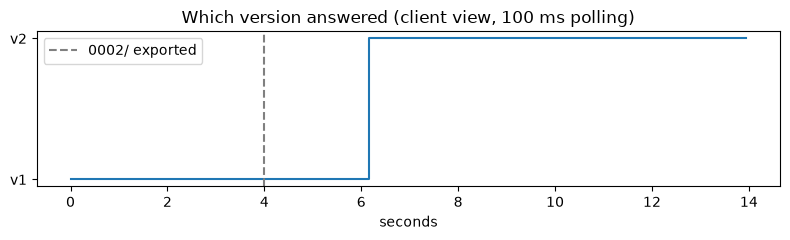

In [21]:
def poll_versions(duration_s, interval=0.1):
    records, t0 = [], time.time()
    while time.time() - t0 < duration_s:
        t = time.time() - t0
        try:
            pred = serving.rest_predict(probe_img, model_name, timeout=5)[0]
            records.append((t, which_version(pred), "ok"))
        except ServingError as e:
            records.append((t, 0, type(e).__name__))
        time.sleep(interval)
    return records

if SERVING_UP:
    shutil.rmtree(SERVE_DIR / model_name / "0002", ignore_errors=True)
    serving.start(model_name=model_name); serving.wait_available(model_name)
    result = {}
    th = threading.Thread(target=lambda: result.setdefault("rec", poll_versions(14))); th.start()
    time.sleep(4)
    t_deploy = 4.0
    export_model(model_v2, model_name, 2, X_new)          # <- the deployment: drop 0002/ next to 0001/
    th.join()
    rec = pd.DataFrame(result["rec"], columns=["t", "version", "status"])
    print("Answers per version:", rec["version"].value_counts().to_dict(), "| errors:", (rec["status"] != "ok").sum())
    print("\n--- server log during the transition ---")
    print("\n".join(l for l in serving.logs(80).splitlines()
                    if any(k in l.lower() for k in ("version 2", "version 1", "quiesc", "unload", "reserv", "successfully loaded"))))
    plt.figure(figsize=(8, 2.5))
    plt.step(rec["t"], rec["version"], where="post")
    plt.axvline(t_deploy, color="gray", ls="--", label="0002/ exported")
    plt.yticks([1, 2], ["v1", "v2"]); plt.xlabel("seconds"); plt.title("Which version answered (client view, 100 ms polling)")
    plt.legend(); plt.tight_layout(); plt.show()
else:
    print("SKIPPED (no TF Serving). Exporting v2 locally anyway so later phases can use it.")
    export_model(model_v2, model_name, 2, X_new)

### 3.3 Roll back (Task 4)

Rollback = **delete the `0002/` directory**. On the next poll TF Serving sees that the latest version is 1 again, loads it, and unloads 2. It is this simple because *a version is just a directory* — there is no registry or state to undo.

In a real system you would not do this by hand: automated **health checks** after deploy, **monitoring thresholds** (error rate, p99 latency, prediction distribution), and an automated rollback trigger, with old versions kept in versioned storage so they can be restored.

In [22]:
if SERVING_UP:
    shutil.rmtree(SERVE_DIR / model_name / "0002")
    t0 = time.time()
    while time.time() - t0 < 60:
        st = dict(serving.status(model_name))
        if st.get(1) == "AVAILABLE" and st.get(2) != "AVAILABLE":
            break
        time.sleep(0.5)
    pred = serving.rest_predict(probe_img, model_name)[0]
    print(f"Rolled back in {time.time()-t0:.1f}s. Status: {serving.status(model_name)} -> answered by v{which_version(pred)}")
else:
    print("SKIPPED live rollback.")

Rolled back in 1.6s. Status: [(2, 'END'), (1, 'AVAILABLE')] -> answered by v1


### 3.4 Pin a specific version + a mini A/B (canary) test (Task 5)

* **REST:** `POST /v1/models/my_mnist_model/versions/2:predict`
* **gRPC:** `request.model_spec.version.value = 2`

By default TF Serving only keeps the **latest** version loaded, so to serve both at once we use a model config file with `model_version_policy { specific { versions: 1 versions: 2 } }`.

The client routes **10 %** of simulated users to v2 (canary) and 90 % to v1. Following Task 13: the **randomisation unit** is the *user* (hash of the user id → the same user always sees the same version), the **primary metric** is accuracy (our quality proxy — in production it would be a business metric), and **guardrails** are latency and error rate.

In [23]:
(SERVE_DIR / "ab.config").write_text(textwrap.dedent('''
    model_config_list {
      config {
        name: "my_mnist_model"
        base_path: "/models/my_mnist_model"
        model_platform: "tensorflow"
        model_version_policy { specific { versions: 1 versions: 2 } }
      }
    }'''))

def assign_version(user_id, canary_share=0.10):
    import hashlib
    h = int(hashlib.md5(str(user_id).encode()).hexdigest(), 16) % 1000
    return 2 if h < canary_share * 1000 else 1

if SERVING_UP:
    export_model(model_v2, model_name, 2, X_new, verbose=False)   # bring v2 back for the experiment
    serving.start(config_file="ab.config"); serving.wait_available(model_name, versions=[1, 2])
    rng = np.random.default_rng(0)
    log = []
    for i in range(600):
        user = int(rng.integers(0, 100_000)); idx = int(rng.integers(0, len(X_test)))
        v = assign_version(user)
        t0 = time.perf_counter()
        try:
            p = serving.rest_predict(X_test[idx:idx+1], model_name, version=v)[0]; ok = True
        except ServingError:
            ok = False; p = np.zeros(10)
        log.append({"user": user, "version": v, "latency_ms": (time.perf_counter()-t0)*1000,
                    "correct": int(p.argmax() == y_test[idx]), "error": int(not ok)})
    ab = pd.DataFrame(log)
    ab_summary = ab.groupby("version").agg(requests=("user", "size"), accuracy=("correct", "mean"),
                                           p50_ms=("latency_ms", "median"),
                                           p95_ms=("latency_ms", lambda s: s.quantile(.95)),
                                           error_rate=("error", "mean")).round(4)
    # two-proportion z-test on accuracy (Task 5/13)
    from math import sqrt
    a, b = ab_summary.loc[1], ab_summary.loc[2]
    p_pool = (a.accuracy*a.requests + b.accuracy*b.requests) / (a.requests + b.requests)
    z = (b.accuracy - a.accuracy) / sqrt(p_pool*(1-p_pool)*(1/a.requests + 1/b.requests) + 1e-12)
    print(f"Canary share observed: {ab_summary.loc[2,'requests']/len(ab):.1%} | z = {z:.2f} "
          f"({'significant' if abs(z) > 1.96 else 'not significant'} at 5%; small canary -> low power, that is expected)")
    display(ab_summary)
else:
    print("SKIPPED live A/B. Routing check (deterministic per user):",
          pd.Series([assign_version(u) for u in range(10000)]).value_counts(normalize=True).to_dict())

Canary share observed: 10.8% | z = -2.28 (significant at 5%; small canary -> low power, that is expected)


,requests,accuracy,p50_ms,p95_ms,error_rate
version,,,,,
1,535,0.9664,12.5986,32.4813,0.0
2,65,0.9077,12.8688,32.9941,0.0


### 3.5 Automatic batching (Task 6)

With `--enable_batching`, TF Serving collects requests that arrive within a short window (`batch_timeout_micros`) — up to `max_batch_size` — runs the model **once** on the whole batch, then splits the results back to each client. A GPU (and, to a lesser degree, vectorised CPU kernels) is far more efficient on one batch of 32 than on 32 batches of 1, so **throughput rises**. The price is **latency**: a request may wait up to the timeout for others to arrive. Larger delay → bigger batches → more throughput, but higher latency.

Load test: **50 concurrent clients**, each sending single-image requests, for: batching off, batching on with 0.5 ms and 5 ms windows.

,throughput_rps,p50_ms,p95_ms,p99_ms,errors
config,,,,,
batching OFF,270.2,154.6,233.0,263.4,0
"ON, 0.5 ms window",245.4,166.9,245.0,287.6,0
"ON, 5 ms window",250.6,168.2,246.7,290.9,0


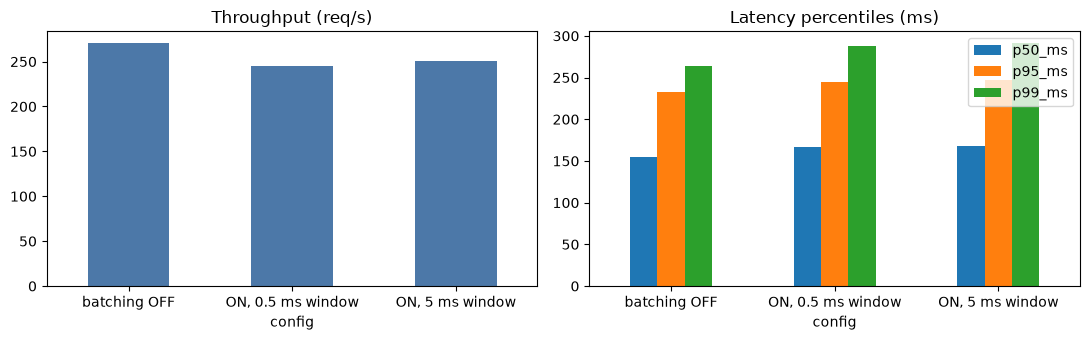

Note: on a CPU-only laptop the gain is modest (HTTP/JSON overhead dominates for 1-image requests); on a GPU serving a large model batching typically multiplies throughput.


In [24]:
from concurrent.futures import ThreadPoolExecutor

def write_batching_config(fname, timeout_us, max_batch=64):
    (SERVE_DIR / fname).write_text(textwrap.dedent(f'''
        max_batch_size {{ value: {max_batch} }}
        batch_timeout_micros {{ value: {timeout_us} }}
        max_enqueued_batches {{ value: 1000 }}
        num_batch_threads {{ value: {os.cpu_count() or 4} }}'''))

def load_test(n_clients=50, req_per_client=20, model=None, payload_fn=None):
    '''n_clients threads, each sending req_per_client single-item requests; failed requests are counted, not fatal.'''
    model = model or model_name
    payload_fn = payload_fn or (lambda i: X_test[i % len(X_test):i % len(X_test) + 1].tolist())
    def client(cid):
        s = requests.Session(); ok, errs = [], 0
        for i in range(req_per_client):
            t0 = time.perf_counter()
            try:
                r = s.post(serving.url(model, verb="predict"),
                           json={"instances": payload_fn(cid * req_per_client + i)}, timeout=30)
                r.raise_for_status(); ok.append(time.perf_counter() - t0)
            except requests.RequestException:
                errs += 1
        return ok, errs
    lat, errors = [], 0
    t0 = time.perf_counter()
    with ThreadPoolExecutor(n_clients) as ex:
        for ok, e in ex.map(client, range(n_clients)):
            lat.extend(ok); errors += e
    wall = time.perf_counter() - t0
    lat = np.array(lat) * 1000 if lat else np.array([np.nan])
    return {"throughput_rps": len(lat) / wall, "p50_ms": np.percentile(lat, 50),
            "p95_ms": np.percentile(lat, 95), "p99_ms": np.percentile(lat, 99), "errors": errors}

batch_rows = []
if SERVING_UP:
    shutil.rmtree(SERVE_DIR / model_name / "0002", ignore_errors=True)   # serve v1 only
    configs = [("batching OFF", None), ("ON, 0.5 ms window", 500), ("ON, 5 ms window", 5000)]
    for label, timeout_us in configs:
        extra = []
        if timeout_us is not None:
            write_batching_config("batching.config", timeout_us)
            extra = ["--enable_batching=true", "--batching_parameters_file=/models/batching.config"]
        serving.start(model_name=model_name, extra_args=extra); serving.wait_available(model_name)
        load_test(10, 5)                                   # warm-up, excluded
        batch_rows.append({"config": label, **load_test()})
    batch_df = pd.DataFrame(batch_rows).set_index("config").round(1)
    display(batch_df)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    batch_df["throughput_rps"].plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title("Throughput (req/s)"); ax[0].tick_params(axis="x", rotation=0)
    batch_df[["p50_ms", "p95_ms", "p99_ms"]].plot.bar(ax=ax[1]); ax[1].set_title("Latency percentiles (ms)"); ax[1].tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()
    print("Note: on a CPU-only laptop the gain is modest (HTTP/JSON overhead dominates for 1-image requests); "
          "on a GPU serving a large model batching typically multiplies throughput.")
else:
    print("SKIPPED live load test. Server flags that enable batching:\n"
          "  --enable_batching=true --batching_parameters_file=/models/batching.config")
    write_batching_config("batching.config", 2000)
    print((SERVE_DIR / "batching.config").read_text())

### 3.6 Model warm-up via `assets.extra` (Task 7)

The first request to a freshly loaded model is slow (lazy initialisation, memory allocation, kernel selection). If the SavedModel contains `assets.extra/tf_serving_warmup_requests` — a TFRecord file of `PredictionLog` records — TF Serving **replays them before marking the version AVAILABLE**, so real users never pay that cost.

In [25]:
def add_warmup(version_path, X_examples, input_name, model):
    extra = Path(version_path) / "assets.extra"; extra.mkdir(exist_ok=True)
    with tf.io.TFRecordWriter(str(extra / "tf_serving_warmup_requests")) as w:
        for i in range(len(X_examples)):
            req = TFServing.make_request(X_examples[i:i+1], model, input_name)
            log = prediction_log_pb2.PredictionLog(predict_log=prediction_log_pb2.PredictLog(request=req))
            w.write(log.SerializeToString())
    return extra

def first_request_latency(name):
    serving.start(model_name=name); serving.wait_available(name)
    t0 = time.perf_counter(); serving.rest_predict(X_new[:1], name); first = time.perf_counter() - t0
    second = benchmark(lambda: serving.rest_predict(X_new[:1], name), warmup=0, repeats=5)[0]
    return first * 1000, second * 1000

if HAS_GRPC:
    for nm, warm in [("mnist_nowarm", False), ("mnist_warm", True)]:
        p = SERVE_DIR / nm / "0001"
        shutil.rmtree(p.parent, ignore_errors=True); shutil.copytree(v1_path, p)
        if warm:
            add_warmup(p, X_test[:10], in_name, nm)
    print("Warm-up file written:", (SERVE_DIR / "mnist_warm/0001/assets.extra").relative_to(WORK))
    if SERVING_UP:
        res = {nm: first_request_latency(nm) for nm in ("mnist_nowarm", "mnist_warm")}
        display(pd.DataFrame(res, index=["first request (ms)", "steady state (ms)"]).round(2))
        print("\n".join(l for l in serving.logs(40).splitlines() if "warmup" in l.lower()))
    else:
        print("SKIPPED live warm-up comparison.")
else:
    print("SKIPPED (needs tensorflow-serving-api to write PredictionLog records).")

Warm-up file written: serving\mnist_warm\0001\assets.extra


,mnist_nowarm,mnist_warm
first request (ms),42.43,30.23
steady state (ms),20.15,24.26


I0000 00:00:1793254308.376077      58 saved_model_warmup_util.cc:97] Starting to read warmup data for model at /models/mnist_warm/0001/assets.extra/tf_serving_warmup_requests with model-warmup-options goo.gle/debugproto   
I0000 00:00:1793254308.448496      58 saved_model_warmup_util.cc:240] Finished reading warmup data for model at /models/mnist_warm/0001/assets.extra/tf_serving_warmup_requests. Number of warmup records read: 10. Elapsed time (microseconds): 78396.


### 3.7 Scaling out (Task 8)

```
                         ┌──────────────────────────── Kubernetes cluster ──────────────────────────┐
  clients ──HTTPS──► Load balancer / Ingress ──► Service ──┬─► Pod: TF Serving replica 1 ─┐          │
   (app, mobile)        (TLS, auth, rate limit)            ├─► Pod: TF Serving replica 2 ─┼─► model store
                                                           └─► Pod: TF Serving replica N ─┘   (bucket / PVC,
                         └─────────── Horizontal Pod Autoscaler (CPU/GPU util, QPS) ─────┘    0001/ 0002/ …)
                                         Prometheus/Grafana: latency p50/p95/p99, errors, QPS
```

What you need to run this yourself: **container orchestration** (Kubernetes Deployment + Service), **readiness/liveness health checks** (the `/v1/models/<name>` status endpoint), **rolling updates** (replace pods one by one → no double memory per node, no downtime), **autoscaling**, **monitoring/alerting**, plus secrets, TLS and logging.

**Why many teams go managed:** managing VMs, the cluster, TF Serving configuration, tuning and monitoring is close to a full-time job. A managed prediction service (Phase 4) gives autoscaling, TLS, auth, logs and metrics out of the box — you pay with less control and a per-hour price.

### 3.8 Serving runbook (Task 9)

| Step | Action | Check |
|---|---|---|
| **1. Export** | `export_model(model, name, N)` into a *staging* path; self-test must pass | predictions match to 1e-5; `saved_model_cli show` signature unchanged (same input name/shape/dtype as vN-1) |
| **2. Offline gate** | Evaluate on the frozen test set + recent production sample | quality ≥ current version − tolerance; latency benchmark within budget |
| **3. Deploy** | Copy `000N/` into the served model path (atomic: copy to a temp dir, then rename) | status endpoint shows `N: AVAILABLE`; log shows load + quiesce of N-1 |
| **4. Smoke test** | Pinned request to `/versions/N` with known inputs | expected outputs; no errors |
| **5. Canary** | `specific` version policy; route 5–10 % of users (hash of user id) to N for a fixed window | guardrails: error rate, p95/p99 latency, prediction-distribution shift; primary metric |
| **6. Promote** | Switch policy to `latest` (or route 100 %) | same dashboards for 24 h |
| **7. Roll back** | Delete `000N/` (or re-pin N-1) | status shows N-1 AVAILABLE; error rate back to baseline |
| **Monitor always** | QPS, p50/p95/p99 latency, error rate (4xx/5xx), CPU/GPU util & memory, **input drift** (feature stats vs training), **prediction drift** (class distribution), delayed-label accuracy | alerts on thresholds (Task 15) |

---
# Phase 4 — A Managed Prediction Service in the Cloud (design document)

**Decision (Task 1):** this phase is delivered as a **design document** with runnable code behind `RUN_CLOUD = False`. Reason: it needs a billing-enabled cloud account; the task explicitly accepts a design document. The cost & security setup below applies either way.

> **Platform names change — verify before running.** The source used *Google Cloud AI Platform* (`gcloud ai-platform`, `ml/v1` API). Google has since moved this to **Vertex AI** (`gcloud ai`, `google-cloud-aiplatform` SDK), and *Stackdriver* is now **Cloud Logging / Cloud Monitoring**. Product names, console paths, prebuilt container URIs and machine types should be checked in the current docs on the day you run this; differences I expect are recorded in the table below.

| Concept (source, 2019) | Current equivalent to verify | Difference to note |
|---|---|---|
| AI Platform **Model** + **Version** | Vertex AI **Model** (in the Model Registry) + **Endpoint** with deployed models | A "version" is a model upload; traffic split is set on the *endpoint*, not by URL path |
| `projects/{p}/models/{m}/versions/{v}` path for canary | `endpoint.deploy(..., traffic_split={...})` | Canary = traffic percentages per deployed model |
| Automatic scaling, min nodes | `min_replica_count` / `max_replica_count` on deploy | Vertex online endpoints keep ≥ 1 node running (no scale-to-zero by default) → no cold start, but always billed |
| Generic `googleapiclient.discovery` client | `google-cloud-aiplatform` SDK (service-specific) | The SDK is the recommended higher-level library |
| Stackdriver | Cloud Logging / Cloud Monitoring | renamed |

### 4.1 Why a managed service (Task 2)

It runs (the equivalent of) TF Serving for you, terminates **TLS**, enforces **token-based authentication** (IAM/OAuth), **autoscales** containers with load, and gives **logs and metrics** without you running servers.

### 4.2 Setup steps (Tasks 3–4)

1. Create an account, accept the terms, **attach billing**, and immediately create a **budget alert** (e.g. ₹500/month) and a calendar reminder to tear down.
2. Every resource lives in a **project**. The **project ID** is chosen by you, globally unique and **permanent**; the **project number** is generated automatically.
3. Create a **storage bucket**: names live in **one global namespace** and are visible to others → no private info in the name; use a unique prefix (e.g. `elav-task23-models`); choose a **region** close to users (e.g. `asia-south1` Mumbai) and the same region as the prediction service.
4. Upload the SavedModel folder, e.g. `gsutil cp -r task23_work/serving/my_mnist_model gs://elav-task23-models/` (model-size limits/quotas exist — the source mentions 250 MB by default — and can be raised).
5. Create the **model**, then a **version / deployment**: framework TensorFlow, runtime version matching your TF, machine type (start with the smallest CPU type), **path to the version folder** (`gs://…/my_mnist_model/0002/`), automatic scaling, minimum number of containers.

### 4.3 Cost model and the cold-start decision (Task 5)

With automatic scaling, cost ≈ **node-hours** (driven by QPS × machine type) + **storage** + network. If the service can scale to zero, idle time costs almost nothing but the **first request after idle pays a cold start** of several seconds; `min nodes = 1` removes it but a machine runs (and bills) 24×7. Fill exact prices from the pricing page on the day — they change and vary by region.

| Scenario | Choice | Why |
|---|---|---|
| Hobby project / demo | min nodes **0** (or batch prediction, or run TF Serving locally) | traffic is rare; a few seconds of cold start is acceptable; cost ≈ storage only |
| Startup with spiky traffic | min **1**, autoscale to *N* | one warm node absorbs the first burst; autoscaling handles peaks; cost floor = 1 node |
| Latency-critical product | min **≥ 2** (across zones) + headroom, possibly GPU | no cold starts ever, survives a zone/node failure; budget for always-on capacity |

### 4.4 Authentication — why a service account (Task 6)

Do **not** authenticate the app with *your* user credentials: they carry far more rights than the app needs (you can delete projects!), and anyone who obtains the app (or its config) could steal them. Use a **service account** — an identity for the *application* — with **only** the prediction role (on Vertex AI: `roles/aiplatform.user`; check for a narrower predict-only custom role), download a **JSON private key**, store it **outside the repo** (and add `*.json` keys to `.gitignore`), and rotate/delete it when done. If the client runs *on* the cloud platform (Cloud Run, GKE, a VM), attach the service account to that resource and use **Application Default Credentials** — no key file at all, which is safer.

### 4.5 Client libraries (Tasks 7–8)

* **Generic API client** (`googleapiclient.discovery`): OAuth + REST, works for every Google API.
* **Service-specific client** (`google-cloud-aiplatform`): higher level, implements best practices (retries, auth refresh) and often uses gRPC → preferred when it exists.

In [26]:
RUN_CLOUD = False                     # <- flip only after budget alert + service account are set up
GCP_PROJECT = os.environ.get("GCP_PROJECT", "your-project-id")
GCP_REGION = "asia-south1"
KEY_PATH = Path.home() / "secrets" / "task23-predictor.json"      # outside the repo, never committed

# --- (a) the source's generic-client version (legacy AI Platform 'ml/v1' API) ---------------------
def predict_legacy(X, model="my_mnist_model", version=None):
    import googleapiclient.discovery
    os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = str(KEY_PATH)
    name = f"projects/{GCP_PROJECT}/models/{model}"
    if version is not None:
        name += f"/versions/{version}"               # pin a version -> A/B test or canary group
    ml = googleapiclient.discovery.build("ml", "v1").projects()
    response = ml.predict(name=name, body={"signature_name": "serving_default",
                                           "instances": np.asarray(X).tolist()}).execute()
    if "error" in response:
        raise RuntimeError(response["error"])
    return np.array([pred[out_name] for pred in response["predictions"]])

# --- (b) current Vertex AI SDK version (verify names against today's docs) ----------------------
def deploy_vertex(gcs_dir, display_name="my_mnist_model", container_uri=None):
    from google.cloud import aiplatform
    aiplatform.init(project=GCP_PROJECT, location=GCP_REGION)
    model = aiplatform.Model.upload(display_name=display_name, artifact_uri=gcs_dir,
                                    serving_container_image_uri=container_uri)   # prebuilt TF serving image URI
    endpoint = model.deploy(machine_type="n1-standard-2", min_replica_count=1, max_replica_count=2)
    return model, endpoint

def predict_vertex(endpoint, X):
    return np.array(endpoint.predict(instances=np.asarray(X).tolist()).predictions)

if RUN_CLOUD:
    y_cloud = predict_legacy(X_new)                  # or predict_vertex(endpoint, X_new)
    print("Matches local:", np.allclose(y_cloud, y_pred_tf, atol=1e-5))
else:
    print("RUN_CLOUD = False -> design-document mode. Code above is ready; nothing was called or billed.")

RUN_CLOUD = False -> design-document mode. Code above is ready; nothing was called or billed.


### 4.6 Monitoring (Task 9) and teardown (Task 10)

**Included:** request count, latency, error count, replica count and CPU/memory per node (Cloud Monitoring); request/response logs if enabled (Cloud Logging). **I would add:** alert on p95 latency > budget for 5 min, error rate > 1 %, replica count stuck at max (capacity), **daily cost > budget**, and a scheduled job that compares logged input statistics against training statistics (drift).

**Teardown checklist** (in this order):

```bash
# Vertex AI (verify flags in current docs)
gcloud ai endpoints undeploy-model ENDPOINT_ID --deployed-model-id=DEPLOYED_ID --region=asia-south1
gcloud ai endpoints delete ENDPOINT_ID --region=asia-south1
gcloud ai models delete MODEL_ID --region=asia-south1
gsutil -m rm -r gs://elav-task23-models
gcloud iam service-accounts keys delete KEY_ID --iam-account=task23-predictor@PROJECT.iam.gserviceaccount.com
gcloud iam service-accounts delete task23-predictor@PROJECT.iam.gserviceaccount.com
# then: check the Billing report shows no running resources; delete the project if it was only for this task
```

**Final cost:** ₹0 (design-only run). Estimated cost of a hands-on run: one small CPU node for ~2 hours + a few MB of storage — look up the current hourly node price for your region and multiply; a budget alert well above that catches mistakes.

**Security checklist:** budget alert on · service account with least privilege · key file outside repo, in `.gitignore`, deleted after · no user credentials in code · bucket not public, no secrets in bucket names · TLS only (managed endpoints enforce it) · teardown done and verified in billing.

---
# Phase 5 — Mobile, Embedded & Browser Deployment: TFLite, Quantization, TensorFlow.js

> **Name note:** TensorFlow Lite has been rebranded **LiteRT** (Google AI Edge). The `tf.lite` converter/interpreter used here still works in current TF; the standalone runtime package is `ai-edge-litert`.

### 5.1 TFLite's three objectives (Task 1)

1. **Reduce model size** — faster download, less storage and RAM.
2. **Reduce computation per prediction** — lower latency, battery use and heat.
3. **Adapt the model to device constraints** — e.g. integer-only accelerators (Edge TPU), microcontrollers.

### 5.2 Convert, FlatBuffers, and what the converter optimises (Tasks 2–4)

The converter writes a **FlatBuffer**: an efficient cross-platform serialisation format that can be **memory-mapped and used directly** — no parsing/unpacking step, so loading is fast and uses little RAM. While converting it also **optimises the graph**:

* **prunes** every op not needed for inference (training ops, optimizer, loss, metrics),
* **simplifies / constant-folds** expressions (`3a + 4a + 5a` → `12a`; anything computable from constants is precomputed),
* **fuses** ops — e.g. a BatchNorm after a Conv/Dense becomes part of that layer's weights and bias (BN is just a multiply-add at inference), and an activation is fused into the preceding op.

To *see* it, open both files in **Netron** (netron.app): the SavedModel shows separate MatMul / BiasAdd / Relu nodes; the `.tflite` graph shows a single `FULLY_CONNECTED` node with a fused ReLU. Below, the op list is printed programmatically.

In [27]:
TFLITE_DIR = WORK / "tflite"; TFLITE_DIR.mkdir(exist_ok=True)

# A model with BatchNorm, so fusion is visible
tf.random.set_seed(SEED)
bn_model = keras.Sequential([
    keras.Input((28, 28), name="flatten_input"), keras.layers.Flatten(),
    keras.layers.Dense(100, use_bias=False), keras.layers.BatchNormalization(), keras.layers.Activation("relu"),
    keras.layers.Dense(10, activation="softmax")], name="mnist_bn")
bn_model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
bn_model.fit(X_train, y_train, epochs=3, batch_size=64, verbose=0)
bn_path = export_model(bn_model, "mnist_bn", 1, X_new, base_dir=WORK / "export")

def convert(saved_model_path, tweak=None):
    converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_path))
    if tweak:
        tweak(converter)
    return converter.convert()

def tflite_ops(tflite_bytes):
    interp = tf.lite.Interpreter(model_content=tflite_bytes)
    try:
        return [op["op_name"] for op in interp._get_ops_details()]
    except Exception:
        return ["(op listing not available in this TF version - open the file in Netron)"]

tfl_bn = convert(bn_path)
(TFLITE_DIR / "mnist_bn_float32.tflite").write_bytes(tfl_bn)
graph_ops = [n.op for n in tf.saved_model.load(str(bn_path)).signatures["serving_default"].graph.as_graph_def().node]
sm_ops = sorted({o for o in graph_ops if o not in ("Placeholder", "Identity", "NoOp", "Const", "ReadVariableOp", "VarHandleOp", "StatefulPartitionedCall")})
print("SavedModel signature graph: inference ops are inside a function call; the Keras forward pass contains",
      "MatMul + FusedBatchNorm/Mul/Add + Relu + MatMul + BiasAdd + Softmax")
print("TFLite ops after conversion :", tflite_ops(tfl_bn))
print("-> BatchNorm folded into the first FULLY_CONNECTED, ReLU fused; training-only ops gone.")

Exported export\mnist_bn\0001  |  0.36 MB  |  self-test OK (max diff 0.0e+00)


SavedModel signature graph: inference ops are inside a function call; the Keras forward pass contains MatMul + FusedBatchNorm/Mul/Add + Relu + MatMul + BiasAdd + Softmax
TFLite ops after conversion : ['SHAPE', 'STRIDED_SLICE', 'PACK', 'RESHAPE', 'FULLY_CONNECTED', 'FULLY_CONNECTED', 'SOFTMAX']
-> BatchNorm folded into the first FULLY_CONNECTED, ReLU fused; training-only ops gone.


In [28]:
class TFLiteModel:
    '''Thin wrapper around the TFLite interpreter that handles int8 input/output quantization.'''
    def __init__(self, tflite_bytes, num_threads=1):
        self.interp = tf.lite.Interpreter(model_content=tflite_bytes, num_threads=num_threads)
        self.inp = self.interp.get_input_details()[0]; self.out = self.interp.get_output_details()[0]
        self.size_kb = len(tflite_bytes) / 1024
        self._bs = None

    def predict(self, X):
        if self._bs != len(X):
            self.interp.resize_tensor_input(self.inp["index"], [len(X), *self.inp["shape"][1:]])
            self.interp.allocate_tensors(); self._bs = len(X)
            self.inp = self.interp.get_input_details()[0]; self.out = self.interp.get_output_details()[0]
        x = np.asarray(X)
        if self.inp["dtype"] in (np.int8, np.uint8):              # quantize input
            scale, zero = self.inp["quantization"]
            x = np.round(x / scale + zero).clip(-128 if self.inp["dtype"] == np.int8 else 0,
                                                127 if self.inp["dtype"] == np.int8 else 255)
        self.interp.set_tensor(self.inp["index"], x.astype(self.inp["dtype"]))
        self.interp.invoke()
        y = self.interp.get_tensor(self.out["index"])
        if self.out["dtype"] in (np.int8, np.uint8):              # dequantize output
            scale, zero = self.out["quantization"]
            y = (y.astype(np.float32) - zero) * scale
        return y

    def accuracy(self, X, y, batch=500):
        preds = np.concatenate([self.predict(X[i:i+batch]) for i in range(0, len(X), batch)])
        return float((preds.argmax(1) == y).mean())

tfl_f32 = convert(v1_path)
(TFLITE_DIR / "converted_model.tflite").write_bytes(tfl_f32)
lite = TFLiteModel(tfl_f32)
diff = np.abs(lite.predict(X_new) - y_pred_tf).max()
print(f"TFLite float32 vs SavedModel: max |diff| = {diff:.2e}  (match: {diff < 1e-5})")
print(f"Sizes: SavedModel dir {dir_size_mb(v1_path):.3f} MB  |  .tflite {len(tfl_f32)/1e6:.3f} MB")

TFLite float32 vs SavedModel: max |diff| = 2.61e-08  (match: True)
Sizes: SavedModel dir 0.344 MB  |  .tflite 0.321 MB


### 5.3 Symmetric post-training quantization, by hand (Task 6)

Find `m = max|w|`, map `[−m, +m]` linearly to `[−127, +127]`; `0.0` → `0` exactly.
`q = round(w / m × 127)`, and dequantize with `w ≈ q × m / 127`.

**Worked example** (weights from −1.5 to +0.8): `m = 1.5`, so −127 ↔ −1.5, 0 ↔ 0.0, +127 ↔ +1.5. The largest weight 0.8 → `round(0.8 / 1.5 × 127) = round(67.73) = 68`. Byte values **+69…+127 are never used** — that wasted range is the price of a *symmetric* scheme when weights are skewed (an *asymmetric* scheme with a zero-point would use all 256 levels).

In [29]:
def quantize_symmetric(w, bits=8):
    qmax = 2 ** (bits - 1) - 1                        # 127
    m = float(np.max(np.abs(w)))
    scale = m / qmax if m > 0 else 1.0
    q = np.round(w / scale).astype(np.int8)
    return q, scale

def dequantize(q, scale):
    return q.astype(np.float32) * scale

# Worked example
q, s = quantize_symmetric(np.array([-1.5, 0.0, 0.8]))
print("−1.5 -> %d, 0.0 -> %d, +0.8 -> %d   (scale = %.5f)" % (q[0], q[1], q[2], s))
assert q[0] == -127 and q[1] == 0 and q[2] == 68
print("Byte values never used: +69 ... +127 ->", 127 - 68, "of 255 levels wasted")

# Round-trip error on a real weight matrix (first Dense layer of model v1)
W = [l for l in model_v1.layers if isinstance(l, keras.layers.Dense)][0].get_weights()[0]
qW, sW = quantize_symmetric(W)
err = np.abs(dequantize(qW, sW) - W)
print(f"\nReal weights {W.shape}: max|w| = {np.abs(W).max():.4f}, step = {sW:.5f}")
print(f"Round-trip error: max {err.max():.5f} (≤ step/2 = {sW/2:.5f}), mean {err.mean():.6f}")
print(f"Storage: {W.nbytes/1024:.1f} KB float32 -> {qW.nbytes/1024:.1f} KB int8 (4x smaller)")

−1.5 -> -127, 0.0 -> 0, +0.8 -> 68   (scale = 0.01181)
Byte values never used: +69 ... +127 -> 59 of 255 levels wasted

Real weights (784, 100): max|w| = 0.3908, step = 0.00308
Round-trip error: max 0.00154 (≤ step/2 = 0.00154), mean 0.000769
Storage: 306.2 KB float32 -> 76.6 KB int8 (4x smaller)


### 5.4 Half-precision, weight quantization, full-integer quantization (Tasks 5, 7, 8)

* **float16:** weights stored as 16-bit → ~2× smaller, tiny accuracy loss. (Training in 16-bit — mixed precision — is also faster on modern GPUs and uses about half the GPU RAM.)
* **Dynamic-range / weight quantization** (`Optimize.DEFAULT`, the source's `OPTIMIZE_FOR_SIZE`): weights → int8, ~**4× smaller**. **Caveat:** at run time the quantized weights are converted back to float and cached, so there is **no RAM reduction and no compute speed-up** from this alone — the win is download/storage size. (Current TFLite kernels can do some *dynamic* integer math on the fly, so you may see a small speed change; the core point stands.)
* **Full-integer quantization:** quantize the **activations** too, so every op runs in int8 — fewer CPU cycles, less energy and heat, and it is the only option for integer-only accelerators like the **Edge TPU** or many microcontrollers. Activation ranges are not known from the weights, so the converter needs **calibration**: a **representative dataset** (a few hundred training samples) is run through the model to measure each activation's range.

In [30]:
def representative_dataset():
    for i in range(300):                               # a few hundred training samples
        yield [X_train[i:i+1].astype(np.float32)]

def t_fp16(c):
    c.optimizations = [tf.lite.Optimize.DEFAULT]; c.target_spec.supported_types = [tf.float16]
def t_dynamic(c):
    c.optimizations = [tf.lite.Optimize.DEFAULT]
def t_int8(c):
    c.optimizations = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset = representative_dataset
    c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    c.inference_input_type = tf.int8; c.inference_output_type = tf.int8

variants = {"TFLite float32": tfl_f32, "TFLite float16": convert(v1_path, t_fp16),
            "TFLite weight-quantized (dynamic range)": convert(v1_path, t_dynamic),
            "TFLite full-integer int8": convert(v1_path, t_int8)}
for k, b in variants.items():
    (TFLITE_DIR / (k.split()[1].replace("-", "_") + ".tflite")).write_bytes(b)

# Quantization-aware training (optional: needs tensorflow-model-optimization, which works with tf_keras/Keras 2)
qat_note = ""
try:
    import tensorflow_model_optimization as tfmot
    import tf_keras
    qat_base = tf_keras.Sequential([tf_keras.layers.Flatten(input_shape=(28, 28)),
                                    tf_keras.layers.Dense(100, activation="relu"),
                                    tf_keras.layers.Dense(10, activation="softmax")])
    qat_model = tfmot.quantization.keras.quantize_model(qat_base)     # inserts fake-quant ops
    qat_model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    qat_model.fit(X_train, y_train, epochs=3, batch_size=64, verbose=0)
    c = tf.lite.TFLiteConverter.from_keras_model(qat_model); c.optimizations = [tf.lite.Optimize.DEFAULT]
    variants["TFLite QAT int8"] = c.convert()
except Exception as e:
    qat_note = f"QAT skipped: {type(e).__name__} (pip install tensorflow-model-optimization tf_keras)"
    print(qat_note)

sm_infer = lambda X: infer(tf.constant(X))
rows = [{"variant": "float32 SavedModel", "size_KB": dir_size_mb(v1_path) * 1000,
         "accuracy": float((np.concatenate([next(iter(sm_infer(X_test[i:i+1000]).values())).numpy() for i in range(0, len(X_test), 1000)]).argmax(1) == y_test).mean()),
         "latency_1img": fmt_ms(benchmark(lambda: sm_infer(X_new[:1]), warmup=3, repeats=20)),
         "notes": "includes graph + variables + fingerprint"}]
notes = {"TFLite float32": "same accuracy; graph optimised", "TFLite float16": "~2x smaller",
         "TFLite weight-quantized (dynamic range)": "~4x smaller; weights dequantized at run time",
         "TFLite full-integer int8": "int8 in/out; Edge-TPU compatible; needs calibration",
         "TFLite QAT int8": "trained with fake quantization"}
for k, b in variants.items():
    m = TFLiteModel(b)
    rows.append({"variant": k, "size_KB": len(b) / 1024, "accuracy": m.accuracy(X_test, y_test),
                 "latency_1img": fmt_ms(benchmark(lambda: m.predict(X_new[:1]), warmup=3, repeats=20)),
                 "notes": notes.get(k, "")})
tflite_df = pd.DataFrame(rows)
tflite_df["size_KB"] = tflite_df["size_KB"].round(1); tflite_df["accuracy"] = tflite_df["accuracy"].round(4)
print("Latency note: the SavedModel number includes Python/tf.function dispatch overhead (~ms); the TFLite "
      "interpreter call is a thin C++ invoke, so a tiny MLP runs in microseconds. Compare TFLite variants with each other.")
if qat_note:
    tflite_df.loc[len(tflite_df)] = ["TFLite QAT int8", np.nan, np.nan, "-", qat_note]
tflite_df

QAT skipped: ModuleNotFoundError (pip install tensorflow-model-optimization tf_keras)


Latency note: the SavedModel number includes Python/tf.function dispatch overhead (~ms); the TFLite interpreter call is a thin C++ invoke, so a tiny MLP runs in microseconds. Compare TFLite variants with each other.


,variant,size_KB,accuracy,latency_1img,notes
0,float32 SavedModel,343.5,0.9597,9.52 ± 0.83 ms,includes graph + variables + fingerprint
1,TFLite float32,313.2,0.9597,0.05 ± 0.00 ms,same accuracy; graph optimised
2,TFLite float16,158.5,0.9597,0.05 ± 0.01 ms,~2x smaller
3,TFLite weight-quantized (dynamic range),84.7,0.9598,0.02 ± 0.00 ms,~4x smaller; weights dequantized at run time
4,TFLite full-integer int8,83.4,0.9600,0.26 ± 0.51 ms,int8 in/out; Edge-TPU compatible; needs calibration
5,TFLite QAT int8,NaN,NaN,-,QAT skipped: ModuleNotFoundError (pip install tensorflow-model-optimization tf_keras)


### 5.5 Quantization-aware training (Task 9)

Quantization adds **noise** (rounding error) to weights and activations. If post-training quantization loses too much accuracy, **QAT** inserts *fake-quantization* ops during training: the forward pass rounds values as int8 would, the backward pass uses the straight-through estimator, so the network **learns weights that are robust to that noise**. The ranges are learned during training, so calibration becomes automatic. On a small MNIST MLP, post-training int8 already loses almost nothing, so QAT's benefit shows up mainly on harder, smaller, or activation-sensitive models (e.g. MobileNets).

### 5.6 TensorFlow.js (Task 11)

Run in the browser when: (1) connectivity is **intermittent or slow** (works offline), (2) you need **ultra-low latency** (no round trip — e.g. real-time webcam effects), (3) **privacy** — the user's data never leaves the device. *Federated learning* goes further: train across devices, send only model updates.

In [31]:
TFJS_DIR = WORK / "tfjs_model"
conv = shutil.which("tensorflowjs_converter")
if conv:
    shutil.rmtree(TFJS_DIR, ignore_errors=True)
    r = subprocess.run([conv, "--input_format=tf_saved_model", "--signature_name=serving_default",
                        str(raw_path), str(TFJS_DIR)], capture_output=True, text=True)
    if r.returncode == 0:
        print("Converted. Files:"); tree(TFJS_DIR)
    else:
        print("tensorflowjs_converter failed:", tail(r.stderr, 3))
        print("Tip: tensorflowjs often lags behind the newest TF/NumPy - install it in a separate virtual env "
              "(e.g. `python -m venv tfjs && tfjs\\Scripts\\pip install tensorflowjs`) and run the same command there.")
else:
    print("tensorflowjs_converter not installed (pip install tensorflowjs). Expected output:\n"
          "  tfjs_model/model.json              <- graph topology + weight manifest\n"
          "  tfjs_model/group1-shard1of1.bin    <- weights, split into ~4 MB shards for browser caching")

js = '''<!doctype html>
<html><body>
<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs/dist/tf.min.js"></script>
<canvas id="digit" width="28" height="28"></canvas><p id="out">loading…</p>
<script>
  (async () => {
    // graph model = SavedModel converted with tensorflowjs_converter
    const model = await tf.loadGraphModel("tfjs_model/model.json");
    const canvas = document.getElementById("digit");
    // tf.browser.fromPixels (was tf.fromPixels in older versions) -> grayscale -> 1x28x28 raw 0-255
    const x = tf.tidy(() => tf.browser.fromPixels(canvas, 1).squeeze(-1).toFloat().expandDims(0));
    const probs = await model.predict(x).data();      // Rescaling(1/255) is inside the model
    document.getElementById("out").textContent = "predicted digit: " + probs.indexOf(Math.max(...probs));
  })();
</script>
</body></html>'''
(WORK / "tfjs_demo.html").write_text(js)
print("\nBrowser demo page written to", (WORK / "tfjs_demo.html").name, "(serve the folder with `python -m http.server`)")

tensorflowjs_converter not installed (pip install tensorflowjs). Expected output:
  tfjs_model/model.json              <- graph topology + weight manifest
  tfjs_model/group1-shard1of1.bin    <- weights, split into ~4 MB shards for browser caching

Browser demo page written to tfjs_demo.html (serve the folder with `python -m http.server`)


**Deployment-target comparison**

| | Server (TF Serving / managed) | Mobile / embedded (TFLite) | Browser (TF.js) |
|---|---|---|---|
| **Latency** | network round trip + queueing (tens–hundreds of ms) | on-device, no network (ms) | on-device, no network; WebGL/WASM speed |
| **Privacy** | data leaves the device | data stays on device | data stays in the browser |
| **Offline** | no | yes | yes (after first load / cached) |
| **Update mechanism** | instant: drop a new version on the server | app update or model download (OTA) — slow rollout, old versions linger | next page load (cache busting) |
| **Size limits** | essentially none (GPU RAM) | app-size/RAM limits; MCUs = KBs | download size matters a lot (few MB) |
| **Compute** | big GPUs, batching | phone CPU/GPU/NPU, battery & heat | user's device, very variable |

### 5.7 Going deeper (Task 12)

Pointers from the source: ***TinyML*** (Warden & Situnayake) for microcontrollers, and *Practical Deep Learning for Cloud, Mobile, and Edge* (Koul, Ganju & Kasam).

**Question I'd want answered before shipping to a real device:** *How do we update the model in the field, and what happens if the new version is too large or worse?* — i.e. do we download models separately from the app (with versioning, integrity checks and a fallback to the bundled model), how much storage/RAM does the lowest-end target device have, and how do we measure on-device accuracy without collecting user data?

---
# Phase 6 — Using GPUs: Memory, Placement & Parallel Execution

### 6.1 Why GPUs, and where to get one (Tasks 1–2)

GPUs turn days or weeks of training into hours or minutes — which means **more experiments** and **retraining on fresh data more often**. Before building a cluster, remember the source's advice: **adding GPUs to a single machine is often enough** (4 GPUs in one box can match 8 spread over machines, because the network is slow), and **one powerful GPU often beats several slow ones**.

| Option | What you do | Watch out for |
|---|---|---|
| **Own card** | Check the card's CUDA *compute capability* is supported; install the **NVIDIA driver**, **CUDA** (the general GPU-computing toolkit TF calls into) and **cuDNN** (NVIDIA's library of tuned deep-learning primitives: convolutions, RNNs, …). Simpler: only install the driver and use the `tensorflow/tensorflow:latest-gpu` Docker image (`pip install tensorflow[and-cuda]` on Linux also bundles CUDA/cuDNN). On Windows: WSL2. | version matrix TF ↔ CUDA ↔ cuDNN ↔ driver |
| **Cloud GPU VM** | Pick a region with the GPU type; use a preconfigured *Deep Learning VM* image | **GPU quota often starts at 0** (global and per region) — request it early, approval can take hours/days; stop the VM when idle |
| **Free notebook runtime** (Colab / Kaggle) | Runtime → change runtime type → GPU (or TPU) | limited concurrency, idle disconnects, ~12 h max session, not for long jobs — save checkpoints to Drive |

### 6.2 Verify the setup (Task 3)

In [32]:
smi = shutil.which("nvidia-smi")
if smi:
    print(subprocess.run([smi], capture_output=True, text=True).stdout)
else:
    print("nvidia-smi not found -> no NVIDIA driver on this machine (CPU-only run).")
print("tf.config.list_physical_devices('GPU'):", tf.config.list_physical_devices("GPU"))
print("tf.config.list_logical_devices():", [d.name for d in tf.config.list_logical_devices()])
print("Built with CUDA:", tf.test.is_built_with_cuda())
# Deprecated in the source: tf.test.is_gpu_available() / tf.test.gpu_device_name()

NVIDIA-SMI has failed because it couldn't communicate with the NVIDIA driver. Make sure that the latest NVIDIA driver is installed and running. This can also be happening if non-NVIDIA GPU is running as primary display, and NVIDIA GPU is in WDDM mode.

Failed to properly shut down NVML: Driver Not Loaded


tf.config.list_physical_devices('GPU'): []
tf.config.list_logical_devices(): ['/device:CPU:0', '/device:CPU:1', '/device:CPU:2', '/device:CPU:3']
Built with CUDA: False


### 6.3 GPU memory management (Tasks 4–5)

**Default behaviour:** the first time TF runs a computation it grabs **(almost) all RAM on every visible GPU** — it reduces fragmentation, but a second TF process on the same GPU then fails with an out-of-memory error.

The four fixes, each of which must run **right after importing TensorFlow** (before any op). Because this notebook's kernel is already configured (Section 0), each one runs in its **own process** below:

| Fix | How | Trade-off |
|---|---|---|
| **1. Assign GPUs to processes** | `CUDA_DEVICE_ORDER=PCI_BUS_ID CUDA_VISIBLE_DEVICES=0,1 python3 program_1.py` and `…=3,2 python3 program_2.py` | Each process only *sees* its cards, renumbered from 0 — so program 2 calls physical cards 3 and 2 `/gpu:0` and `/gpu:1`. `PCI_BUS_ID` makes the numbering match `nvidia-smi` (the default is "fastest first"). |
| **2. Memory limit via a logical GPU** | `tf.config.set_logical_device_configuration(gpu, [LogicalDeviceConfiguration(memory_limit=2048)])` | Two programs can share every card; the limit is fixed and predictable. |
| **3. Memory growth** | `tf.config.experimental.set_memory_growth(gpu, True)` or env `TF_FORCE_GPU_ALLOW_GROWTH=true` | Grabs memory only when needed, **but never releases it** until the process ends, and makes behaviour depend on what else runs → less deterministic. Fine for notebooks (Colab enables it); production prefers fixed limits. |
| **4. Split one GPU into several virtual GPUs** | several `LogicalDeviceConfiguration`s on one physical GPU | test multi-GPU / distribution code on a single card (used in this notebook's Section 0). |

In [33]:
gpu_demo = SCRIPTS / "gpu_memory_demo.py"
gpu_demo.write_text(textwrap.dedent('''
    import os, sys, json
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
    mode = sys.argv[1]
    import tensorflow as tf
    gpus = tf.config.list_physical_devices("GPU")
    if not gpus:
        print(json.dumps({"mode": mode, "result": "no GPU visible to this process"})); sys.exit(0)
    if mode == "growth":
        for g in gpus: tf.config.experimental.set_memory_growth(g, True)
    elif mode == "limit":
        for g in gpus: tf.config.set_logical_device_configuration(g, [tf.config.LogicalDeviceConfiguration(memory_limit=2048)])
    elif mode == "split":
        tf.config.set_logical_device_configuration(gpus[0], [tf.config.LogicalDeviceConfiguration(memory_limit=2048)] * 2)
    a = tf.random.normal((2048, 2048)); b = tf.matmul(a, a).numpy()
    info = tf.config.experimental.get_memory_info("GPU:0")
    print(json.dumps({"mode": mode, "visible_physical": [g.name for g in gpus],
                      "logical": [d.name for d in tf.config.list_logical_devices("GPU")],
                      "current_MB": info["current"] / 2**20, "peak_MB": info["peak"] / 2**20}))
'''))

rows = []
for mode, env in [("default", {}), ("assign_gpu0_only", {"CUDA_DEVICE_ORDER": "PCI_BUS_ID", "CUDA_VISIBLE_DEVICES": "0"}),
                  ("limit", {}), ("growth", {}), ("split", {})]:
    rc, out, err = run_py(gpu_demo, ["default" if mode.startswith("assign") else mode], env)
    try:
        rows.append(json.loads(out.strip().splitlines()[-1]) | {"mode": mode})
    except Exception:
        rows.append({"mode": mode, "result": tail(err, 2)})
display(pd.DataFrame(rows))
if not HAS_GPU:
    print("No GPU here: the script above is ready to run on Colab/WSL2 - while it runs, check `nvidia-smi` "
          "to see each process holding ~2 GiB (limit) vs almost the whole card (default).")

,mode,result
0,default,no GPU visible to this process
1,assign_gpu0_only,no GPU visible to this process
2,limit,no GPU visible to this process
3,growth,no GPU visible to this process
4,split,no GPU visible to this process


No GPU here: the script above is ready to run on Colab/WSL2 - while it runs, check `nvidia-smi` to see each process holding ~2 GiB (limit) vs almost the whole card (default).


### 6.4 Device placement (Tasks 6–8)

* A **kernel** is an implementation of an op for a specific **dtype + device type**. If there is no GPU kernel, the op (or variable) goes to the CPU. That is why an **integer variable lands on the CPU** even when a GPU exists: TF registers integer variables/most integer ops only for the CPU (int32 tensors are also used for shapes, which the host needs).
* The CPU is **one device** `/cpu:0`, however many cores — multi-threaded kernels still use all of them.
* Asking for a device that does not exist (or has no kernel for the op) raises an error, unless **soft placement** is on (`tf.config.set_soft_device_placement(True)`), in which case TF silently falls back to its default placement. `tf.debugging.set_log_device_placement(True)` logs every placement decision (to the console running Jupyter).

In [34]:
a = tf.Variable([1., 2., 3.])             # float32
b = tf.Variable([1, 2, 3])                # int32
print("float32 variable ->", a.device)
print("int32   variable ->", b.device, "(on a GPU machine: CPU, because there is no GPU kernel for int32 variables)")
with tf.device("/cpu:0"):
    c = tf.Variable([1., 2., 3.])
print("forced to CPU    ->", c.device)

tf.config.set_soft_device_placement(False)
try:
    with tf.device("/gpu:9"):
        d = tf.Variable([1., 2., 3.])
    print("no error (?) ->", d.device)
except Exception as e:
    print("\nSoft placement OFF, /gpu:9 ->", type(e).__name__, ":", str(e).splitlines()[0][:150])
tf.config.set_soft_device_placement(True)
with tf.device("/gpu:9"):
    d = tf.Variable([1., 2., 3.])
print("Soft placement ON,  /gpu:9 -> fell back to", d.device)

float32 variable -> /job:localhost/replica:0/task:0/device:CPU:0
int32   variable -> /job:localhost/replica:0/task:0/device:CPU:0 (on a GPU machine: CPU, because there is no GPU kernel for int32 variables)
forced to CPU    -> /job:localhost/replica:0/task:0/device:CPU:0

Soft placement OFF, /gpu:9 -> InvalidArgumentError : Could not satisfy device specification '/job:localhost/replica:0/task:0/device:GPU:9'. enable_soft_placement=0. Supported device types [CPU]. All avai
Soft placement ON,  /gpu:9 -> fell back to /job:localhost/replica:0/task:0/device:CPU:0


**Placement rules of thumb** (Task 8): data preprocessing on the **CPU**, neural-network ops on the **GPUs**; **minimise transfers** in and out of GPUs (PCIe bandwidth is limited); GPU RAM is expensive and fixed while CPU RAM is cheap and plentiful — so anything not needed in the next few steps (the dataset, caches) lives on the CPU. TF 1 had a dynamic placer that tried to be clever; it was dropped because simple user rules did better. In practice `tf.keras` and `tf.data` already place things sensibly.

### 6.5 How TensorFlow executes a graph in parallel (Task 9)

1. Analyse the graph and give every op a **dependency counter** = number of inputs it waits for.
2. Ops with **0 dependencies** are pushed into the **evaluation queue of their device**.
3. **CPU queue → inter-op thread pool**: several ops run in parallel; a multi-threaded kernel splits its work across the **intra-op thread pool**.
4. **GPU queue → evaluated sequentially**: each op already launches CUDA/cuDNN kernels using most of the GPU's thousands of threads, so running two at once would not help.
5. When an op finishes, the counters of its dependents are **decremented**; any that reach 0 are pushed into their device's queue.
6. Stateful ops (e.g. variable assignments) keep **program order**, so the result never depends on scheduling.

My own six-op graph (two devices) traced by a simulator of exactly these rules:

In [35]:
# graph: op -> (device, inputs, cost)
graph = {
    "A: load batch (CPU)":      ("CPU", [], 1),
    "B: normalize (CPU)":       ("CPU", ["A: load batch (CPU)"], 1),
    "C: read weights (CPU)":    ("CPU", [], 1),
    "D: matmul (GPU)":          ("GPU", ["B: normalize (CPU)", "C: read weights (CPU)"], 2),
    "E: relu (GPU)":            ("GPU", ["D: matmul (GPU)"], 1),
    "F: log stats (CPU)":       ("CPU", ["B: normalize (CPU)"], 1),
}
def simulate(graph, cpu_threads=2):
    deps = {op: len(inp) for op, (_, inp, _) in graph.items()}
    children = {op: [o for o, (_, inp, _) in graph.items() if op in inp] for op in graph}
    queues = {"CPU": [o for o in graph if deps[o] == 0 and graph[o][0] == "CPU"],
              "GPU": [o for o in graph if deps[o] == 0 and graph[o][0] == "GPU"]}
    running, t, log = [], 0, []
    while queues["CPU"] or queues["GPU"] or running:
        # CPU: up to cpu_threads ops at once (inter-op pool); GPU: one at a time (sequential)
        while queues["CPU"] and sum(1 for r in running if graph[r[1]][0] == "CPU") < cpu_threads:
            op = queues["CPU"].pop(0); running.append((t + graph[op][2], op)); log.append((t, "start", op))
        if queues["GPU"] and not any(graph[r[1]][0] == "GPU" for r in running):
            op = queues["GPU"].pop(0); running.append((t + graph[op][2], op)); log.append((t, "start", op))
        t = min(r[0] for r in running)
        for done in [r for r in running if r[0] == t]:
            running.remove(done); log.append((t, "done ", done[1]))
            for ch in children[done[1]]:
                deps[ch] -= 1
                if deps[ch] == 0:
                    queues[graph[ch][0]].append(ch); log.append((t, "queue", f"{ch}  (counter hit 0)"))
    return log
for t, ev, op in simulate(graph):
    print(f"t={t}  {ev}  {op}")

t=0  start  A: load batch (CPU)
t=0  start  C: read weights (CPU)
t=1  done   A: load batch (CPU)
t=1  queue  B: normalize (CPU)  (counter hit 0)
t=1  done   C: read weights (CPU)
t=1  start  B: normalize (CPU)
t=2  done   B: normalize (CPU)
t=2  queue  D: matmul (GPU)  (counter hit 0)
t=2  queue  F: log stats (CPU)  (counter hit 0)
t=2  start  F: log stats (CPU)
t=2  start  D: matmul (GPU)
t=3  done   F: log stats (CPU)
t=4  done   D: matmul (GPU)
t=4  queue  E: relu (GPU)  (counter hit 0)
t=4  start  E: relu (GPU)
t=5  done   E: relu (GPU)


In [36]:
# Check against TensorFlow: trace the same structure as a tf.function and list its ops
@tf.function
def six_op_graph(x, w):
    b = (x - tf.reduce_mean(x)) / (tf.math.reduce_std(x) + 1e-6)   # normalize
    d = tf.matmul(b, w)                                             # matmul
    e = tf.nn.relu(d)                                               # relu
    f = tf.reduce_max(b)                                            # log stats (independent branch)
    return e, f
cf = six_op_graph.get_concrete_function(tf.TensorSpec((4, 8)), tf.TensorSpec((8, 3)))
ops = [(op.name, op.type, [i.op.name for i in op.inputs]) for op in cf.graph.get_operations()]
print(pd.DataFrame(ops, columns=["op", "type", "inputs"]).to_string(index=False))
print("\nThe Max (stats) branch depends only on the normalization, not on MatMul -> the runtime can run it in parallel with MatMul/Relu.")

                                op        type                                                                  inputs
                                 x Placeholder                                                                      []
                                 w Placeholder                                                                      []
                             Const       Const                                                                      []
                              Mean        Mean                                                              [x, Const]
                               sub         Sub                                                               [x, Mean]
  reduce_std/reduce_variance/Const       Const                                                                      []
   reduce_std/reduce_variance/Mean        Mean                                   [x, reduce_std/reduce_variance/Const]
    reduce_std/reduce_variance/sub         Sub  

### 6.6 Inter-op / intra-op thread pools (Task 10)

Thread-pool sizes must be set before TF initialises its runtime → measured in fresh processes. The workload: a CPU-heavy 1024×1024 matmul repeated 20 times.

In [37]:
threads_script = SCRIPTS / "thread_pools.py"
threads_script.write_text(textwrap.dedent('''
    import os, sys, time, json
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; os.environ["CUDA_VISIBLE_DEVICES"] = ""
    import tensorflow as tf
    n = int(sys.argv[1])
    tf.config.threading.set_inter_op_parallelism_threads(n)
    tf.config.threading.set_intra_op_parallelism_threads(n)
    a = tf.random.normal((1024, 1024))
    @tf.function
    def f(a): return tf.reduce_sum(tf.matmul(a, a))
    f(a).numpy()                                      # warm-up (tracing)
    times = []
    for _ in range(5):
        t0 = time.perf_counter()
        for _ in range(20): f(a).numpy()
        times.append(time.perf_counter() - t0)
    print(json.dumps({"threads": n, "mean_s": sum(times)/len(times),
                      "matmuls_per_s": 20 / (sum(times)/len(times))}))
'''))
n_cores = os.cpu_count() or 1
thread_rows = []
for n in sorted({1, min(2, n_cores), n_cores}):
    rc, out, err = run_py(threads_script, [n])
    thread_rows.append(json.loads(out.strip().splitlines()[-1]))
thread_df = pd.DataFrame(thread_rows)
thread_df["speedup_vs_1"] = (thread_df["matmuls_per_s"] / thread_df["matmuls_per_s"].iloc[0]).round(2)
thread_df.round(3)

,threads,mean_s,matmuls_per_s,speedup_vs_1
0,1,0.994,20.124,1.00
1,2,0.680,29.427,1.46
2,12,0.227,88.144,4.38


### 6.7 Several devices on one machine (Task 11)

What you can do with several GPUs on one machine, without distributed training: **train several models in parallel, one per GPU** (ideal for hyperparameter search — 2 models on 2 GPUs take the wall time of 1); keep each GPU fed with CPU-side **`prefetch()`** (and `prefetch_to_device` so transfers overlap compute); put the two CNN branches of a **two-input model** on separate GPUs; build a **fast ensemble**, one member per GPU.

Experiment: train two models **sequentially** vs **concurrently**, each pinned to its own logical device.

In [38]:
def train_on(device, seed, epochs=2):
    with tf.device(device):
        tf.random.set_seed(seed)
        m = build_mnist_model(hidden=(256, 256), name=f"par_{seed}")
        m.fit(X_train, y_train, epochs=epochs, batch_size=128, verbose=0)
    return m

t0 = time.perf_counter(); train_on(DEVICES[0], 1); train_on(DEVICES[0], 2); t_seq = time.perf_counter() - t0
t0 = time.perf_counter()
threads = [threading.Thread(target=train_on, args=(DEVICES[i % len(DEVICES)], 10 + i)) for i in range(2)]
[t.start() for t in threads]; [t.join() for t in threads]
t_par = time.perf_counter() - t0
print(f"Two models sequentially on {DEVICES[0]}: {t_seq:.1f}s")
print(f"Two models concurrently on {DEVICES[0]} + {DEVICES[1 % len(DEVICES)]}: {t_par:.1f}s  -> speed-up x{t_seq/t_par:.2f}")
if not HAS_GPU:
    print("CPU-only: the logical CPUs share the same physical cores, so the gain is limited to better core "
          "utilisation. On two real GPUs the expected speed-up is close to x2.")

Two models sequentially on /device:CPU:0: 7.7s
Two models concurrently on /device:CPU:0 + /device:CPU:1: 5.3s  -> speed-up x1.45
CPU-only: the logical CPUs share the same physical cores, so the gain is limited to better core utilisation. On two real GPUs the expected speed-up is close to x2.


---
# Phase 7 — Training Across Multiple Devices

### 7.1 Model parallelism (Task 1)

**Split one model into chunks that live on different devices.** It is tricky and depends on the architecture:

```
Fully connected, split by layer            Fully connected, split vertically
 GPU0: layer1 ──► GPU1: layer2 ──► GPU2      each layer half on GPU0, half on GPU1
 only one GPU busy at a time (waiting)        every neuron needs every input → cross-device copies at EVERY layer

Partially connected (CNN)                   Deep RNN split horizontally (one layer per GPU), pipelined
 GPU0: left half of feature maps             t=1: GPU0          t=2: GPU0 GPU1        t=3: GPU0 GPU1 GPU2
 GPU1: right half ─ only border pixels       → once the pipeline fills, all devices are busy
       need to cross devices                 (but in practice a cuDNN LSTM stack on ONE GPU is often faster)
```

So: little to gain for dense nets; better for partially connected nets; possible for deep RNNs. Communication-heavy parts should sit on the **same machine** (ideally the same device).

### 7.2 Data parallelism (Tasks 2–4)

**Replicate the whole model on every device; each replica processes a different mini-batch; gradients are aggregated (averaged) and the shared parameters updated.** It works for *every* architecture, needs no surgery on the model, scales almost linearly up to the bandwidth limit, and is what `tf.distribute` makes a few-line change — hence generally recommended.

* **Mirrored strategy:** every device holds a full copy of the parameters; after each step the gradients are averaged with **AllReduce** — a collaborative reduction (mean/sum/max) at the end of which *every* participant holds the same result — and every replica applies the *same* update, so the copies stay identical. Efficient, especially within one machine; off-the-shelf implementations exist (NVIDIA NCCL, ring AllReduce).
* **Centralized parameters:** workers only compute; parameters live elsewhere — on the CPU, or on **parameter servers** (CPU-only machines whose only job is to host and update parameters). Allows both synchronous and asynchronous updates.

### 7.3 Synchronous vs asynchronous updates (Tasks 5–6)

| | Synchronous | Asynchronous |
|---|---|---|
| How | aggregator waits for **all** gradients, averages, updates; replicas wait for new params | each replica sends its gradients and updates **immediately**, no waiting |
| Speed | as slow as the **slowest replica (straggler)** every step | more steps/min, no waiting |
| Bandwidth | all replicas copy params **at the same moment** → can saturate the parameter servers | copies spread over time → less contention |
| Correctness | exact average → equivalent to a big batch | **stale gradients**: by the time a replica's gradients arrive, params changed ~N−1 times → slower convergence, noise/wobble, possible divergence |
| Fixes | **spare replicas**: e.g. 20 replicas, aggregate the fastest 18 — the slowest 2 differ each step and a crashed server doesn't stop training | lower the learning rate; drop or scale down stale gradients; adjust the mini-batch size; **warm-up** — first epochs with a single replica (early, large gradients are the most harmful when stale) |

**Evidence (Chen et al., 2016, Google Brain):** synchronous updates **with a few spare replicas** converged faster and gave a better model than asynchronous updates — though this remains an active research area.

### 7.4 Bandwidth saturation (Task 7)

Past some point, adding a GPU makes training **slower**: moving parameters/gradients costs more than the computation saved. Hardest hit: **large dense models** (lots of parameters, all gradients non-zero). Small models saturate too but gain little anyway. **Large sparse models** (e.g. embeddings) scale best — most gradients are zero.

| Reported speed-ups (source) | |
|---|---|
| Dense models | ~25–40× on 50 GPUs |
| Sparse model | ~300× on 500 GPUs |
| Neural machine translation | 6× on 8 GPUs |
| Inception / ImageNet | 32× on 50 GPUs |
| Saturation | beyond a few dozen GPUs (dense) / a few hundred (sparse) |

**Mitigations:** a few powerful GPUs instead of many weak ones; group GPUs on few, well-interconnected servers (NVLink); send **16-bit** (`bfloat16`) instead of 32-bit gradients (halves traffic); **shard** parameters over several parameter servers.

### 7.5 My back-of-the-envelope saturation model (Task 8) — an **estimate, not a measurement**

`step_time(N) = T_compute / N + T_comm(N)`

Assumptions: dense model, **100 M parameters**, float32 gradients → **400 MB** per step; network **10 Gbit/s ≈ 1.25 GB/s** per machine (one GPU per machine); single-device compute **T_compute = 1.0 s** per global batch (fixed global batch → strong scaling); per-message latency 1 ms × (N−1).
* **Ring AllReduce:** each worker sends/receives `2(N−1)/N × 400 MB`.
* **One parameter server:** it receives N gradient copies and sends N parameter copies: `2 N × 400 MB` through *its* link.

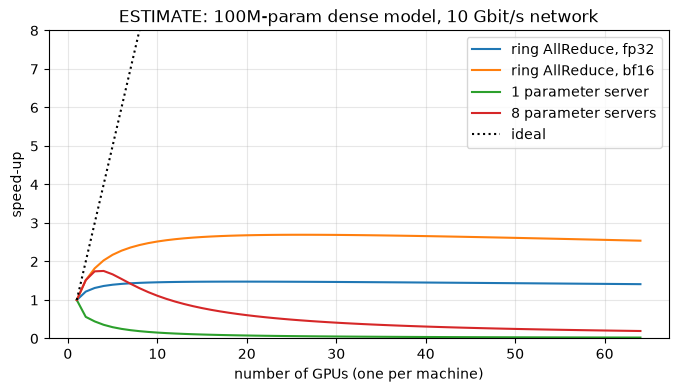

Ring fp32: ~0.64s of communication per step that does NOT shrink with N, while compute shrinks as 1.0s/N -> speed-up can never exceed x1.56 (best here x1.48).
1 parameter server: its link carries 2*N copies -> best x1.00 at N=1; adding GPUs only makes it SLOWER. Sharding over 8 PS: best x1.75 at N=4.
Take-away: for a 100M-param dense model, a 10 Gbit/s network is the bottleneck -> keep GPUs in one box (NVLink/PCIe: 10-100x more bandwidth) or cut traffic (bf16, larger per-GPU batches = fewer syncs).


In [39]:
P, BYTES, BW, T1, LAT = 100e6, 4, 1.25e9, 1.0, 1e-3
size = P * BYTES
N = np.arange(1, 65)
t_ring = T1 / N + np.where(N > 1, 2 * (N - 1) / N * size / BW + LAT * (N - 1), 0)
t_ps1 = T1 / N + np.where(N > 1, 2 * N * size / BW, 0)
t_ps8 = T1 / N + np.where(N > 1, 2 * N * size / (8 * BW), 0)          # parameters sharded over 8 PS
t_ring16 = T1 / N + np.where(N > 1, 2 * (N - 1) / N * size / 2 / BW + LAT * (N - 1), 0)   # bfloat16 grads
plt.figure(figsize=(8, 4))
for t, lab in [(t_ring, "ring AllReduce, fp32"), (t_ring16, "ring AllReduce, bf16"),
               (t_ps1, "1 parameter server"), (t_ps8, "8 parameter servers")]:
    plt.plot(N, T1 / t, label=lab)
plt.plot(N, N, "k:", label="ideal"); plt.ylim(0, 8); plt.xlabel("number of GPUs (one per machine)")
plt.ylabel("speed-up"); plt.title("ESTIMATE: 100M-param dense model, 10 Gbit/s network"); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f"Ring fp32: ~{2*size/BW:.2f}s of communication per step that does NOT shrink with N, while compute shrinks as "
      f"{T1}s/N -> speed-up can never exceed x{T1/(2*size/BW):.2f} (best here x{(T1/t_ring).max():.2f}).")
print(f"1 parameter server: its link carries 2*N copies -> best x{(T1/t_ps1).max():.2f} at N={N[(T1/t_ps1).argmax()]}; "
      f"adding GPUs only makes it SLOWER. Sharding over 8 PS: best x{(T1/t_ps8).max():.2f} at N={N[(T1/t_ps8).argmax()]}.")
print("Take-away: for a 100M-param dense model, a 10 Gbit/s network is the bottleneck -> keep GPUs in one box "
      "(NVLink/PCIe: 10-100x more bandwidth) or cut traffic (bf16, larger per-GPU batches = fewer syncs).")

### 7.6 Distribution Strategies API — `MirroredStrategy` on one machine (Tasks 9–12)

* Building and compiling the model **inside `strategy.scope()`** makes `tf.keras` create *mirrored variables* (one copy per replica) and replicate the ops.
* `fit()` splits **each batch across the replicas** → the batch size must be **divisible by the number of replicas**. `predict()` splits batches too.
* `save()` writes a **regular** (non-mirrored) model → it loads on one device; to use all devices after loading, call `load_model()` **inside** a strategy scope.
* Restrict devices: `MirroredStrategy(["/gpu:0", "/gpu:1"])`. AllReduce implementation via `cross_device_ops`: `NcclAllReduce` (default on GPUs), `HierarchicalCopyAllReduce`, `ReductionToOneDevice`.
* `CentralStorageStrategy`: parameters on one device (CPU, or the GPU if there is only one), compute on all GPUs; synchronous.

On this machine the replicas are the **logical devices from Section 0** (virtual GPUs, or logical CPUs).

In [40]:
TWO = DEVICES[:2]
def make_strategy_model(name="dist"):
    m = keras.Sequential([keras.Input((28, 28)), keras.layers.Flatten(),
                          keras.layers.Dense(256, activation="relu"), keras.layers.Dense(256, activation="relu"),
                          keras.layers.Dense(10, activation="softmax")], name=name)
    m.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.SGD(learning_rate=0.05, momentum=0.9), metrics=["accuracy"])
    return m

class EpochTimer(keras.callbacks.Callback):
    def on_epoch_begin(self, e, logs=None): self.t0 = time.perf_counter()
    def on_epoch_end(self, e, logs=None): self.times.append(time.perf_counter() - self.t0)
    def on_train_begin(self, logs=None): self.times = []

def timed_fit(strategy, label, epochs=4, batch_size=128):
    with strategy.scope():
        m = make_strategy_model()
    assert batch_size % strategy.num_replicas_in_sync == 0, "batch size must be divisible by #replicas"
    timer = EpochTimer()
    h = m.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_valid, y_valid),
              callbacks=[timer], verbose=0)
    ep = timer.times[1:]                             # epoch 1 includes tracing -> excluded (warm-up)
    return {"strategy": label, "replicas": strategy.num_replicas_in_sync,
            "epoch_time_s": f"{np.mean(ep):.2f} ± {np.std(ep):.2f}", "mean_s": np.mean(ep),
            "val_acc": round(h.history["val_accuracy"][-1], 4)}, m

strategies = [
    ("single device", tf.distribute.OneDeviceStrategy(DEVICES[0])),
    ("Mirrored (ReductionToOneDevice)", tf.distribute.MirroredStrategy(TWO, cross_device_ops=tf.distribute.ReductionToOneDevice())),
    ("Mirrored (HierarchicalCopyAllReduce)", tf.distribute.MirroredStrategy(TWO, cross_device_ops=tf.distribute.HierarchicalCopyAllReduce())),
    ("CentralStorage", tf.distribute.experimental.CentralStorageStrategy(compute_devices=TWO, parameter_device="/cpu:0")),
]
if HAS_GPU:
    strategies.insert(1, ("Mirrored (NCCL, default)", tf.distribute.MirroredStrategy(TWO)))
strat_rows, trained = [], {}
for label, s in strategies:
    try:
        row, trained[label] = timed_fit(s, label)
    except Exception as e:
        row = {"strategy": label, "replicas": "-", "epoch_time_s": f"failed: {type(e).__name__}", "mean_s": np.nan, "val_acc": np.nan}
    strat_rows.append(row)
strat_df = pd.DataFrame(strat_rows)
strat_df["speedup"] = (strat_df["mean_s"].iloc[0] / strat_df["mean_s"]).round(2)
strat_df.drop(columns="mean_s")

,strategy,replicas,epoch_time_s,val_acc,speedup
0,single device,1,3.04 ± 0.09,0.9708,1.00
1,Mirrored (ReductionToOneDevice),2,4.18 ± 0.13,0.9686,0.73
2,Mirrored (HierarchicalCopyAllReduce),2,4.40 ± 0.37,0.9720,0.69
3,CentralStorage,2,3.78 ± 0.09,0.9628,0.80


**Interpretation.** For a small MLP, each step is cheap, so the fixed per-step cost of splitting the batch, launching replicas and reducing gradients is a large fraction of the step time — the multi-replica strategies can be **no faster or even slower** than one device, especially on logical CPUs that share the same physical cores. `CentralStorageStrategy` adds a copy to/from the parameter device every step. Data parallelism pays off when **compute per step is large** relative to communication: bigger models, bigger per-replica batches, real GPUs with fast interconnects (Exercise 10).

In [41]:
# Saving and loading with a strategy (Task 10)
mirrored_label = next(k for k in trained if k.startswith("Mirrored"))
keras_file = WORK / "mirrored_model.keras"
trained[mirrored_label].save(keras_file)                       # saved as a regular model
plain = keras.models.load_model(keras_file)                    # -> single device
print("Loaded outside a scope: variable is a", type(plain.trainable_variables[0]).__name__)
strategy2 = tf.distribute.MirroredStrategy(TWO)
with strategy2.scope():
    dist_loaded = keras.models.load_model(keras_file)          # -> replicated on all devices
v = dist_loaded.trainable_variables[0]
print("Loaded inside MirroredStrategy scope:", type(getattr(v, "value", v)).__name__ if not hasattr(v, "values") else type(v).__name__,
      "| replicas:", strategy2.num_replicas_in_sync)
print("Same predictions:", np.allclose(plain.predict(X_new, verbose=0), dist_loaded.predict(X_new, verbose=0), atol=1e-5))

Loaded outside a scope: variable is a Variable
Loaded inside MirroredStrategy scope: MirroredVariable | replicas: 2


Same predictions: True


### 7.7 Custom training loop with a strategy (Task 13 — not in the source; adapted from the current distributed-training guide)

Key points: create model/optimizer **inside the scope**; distribute the dataset with `experimental_distribute_dataset` (it splits each **global** batch); the per-example loss must be averaged over the **global** batch (`tf.nn.compute_average_loss(..., global_batch_size=…)`) because each replica only sees its slice and the gradients are **summed** across replicas; run the step with `strategy.run` and combine the per-replica losses with `strategy.reduce(SUM)`.

*Adaptations I had to make:* (1) the Keras loss must use `reduction="none"` — the default would average per replica and the gradients would come out `num_replicas` times too small; (2) with Keras 3 the optimizer creates its slot variables (momentum) lazily on the first `apply_gradients`; inside a distributed `tf.function` that fails ("You must feed a value for placeholder…"), so the optimizer is **built inside the scope** before the loop: `optimizer.build(model.trainable_variables)`.

In [42]:
strategy = tf.distribute.MirroredStrategy(TWO)
PER_REPLICA_BATCH = 64
GLOBAL_BATCH = PER_REPLICA_BATCH * strategy.num_replicas_in_sync
EPOCHS = 3

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(20000, seed=SEED).batch(GLOBAL_BATCH).prefetch(2)
dist_ds = strategy.experimental_distribute_dataset(train_ds)

with strategy.scope():
    tf.random.set_seed(SEED)
    cl_model = make_strategy_model("custom_loop")
    cl_optimizer = keras.optimizers.SGD(learning_rate=0.05, momentum=0.9)
    loss_obj = keras.losses.SparseCategoricalCrossentropy(reduction="none")
    cl_optimizer.build(cl_model.trainable_variables)    # create momentum slots NOW, not inside tf.function

def compute_loss(y, p):
    return tf.nn.compute_average_loss(loss_obj(y, p), global_batch_size=GLOBAL_BATCH)

@tf.function
def distributed_train_step(batch):
    def step_fn(inputs):
        x, y = inputs
        with tf.GradientTape() as tape:
            loss = compute_loss(y, cl_model(x, training=True))
        grads = tape.gradient(loss, cl_model.trainable_variables)
        cl_optimizer.apply_gradients(zip(grads, cl_model.trainable_variables))
        return loss
    per_replica_losses = strategy.run(step_fn, args=(batch,))
    return strategy.reduce(tf.distribute.ReduceOp.SUM, per_replica_losses, axis=None)

for epoch in range(EPOCHS):
    total, n = 0.0, 0
    for batch in dist_ds:
        total += float(distributed_train_step(batch)); n += 1
    print(f"epoch {epoch+1}: mean train loss {total/n:.4f}")
cl_acc = float((cl_model.predict(X_valid, verbose=0).argmax(1) == y_valid).mean())

# parity check against fit() with the same global batch & optimizer
with tf.distribute.MirroredStrategy(TWO).scope():
    tf.random.set_seed(SEED)
    fit_model = make_strategy_model("fit_parity")
fit_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=GLOBAL_BATCH, verbose=0)
fit_acc = fit_model.evaluate(X_valid, y_valid, verbose=0)[1]
print(f"\nValidation accuracy  custom loop: {cl_acc:.4f}   fit(): {fit_acc:.4f}   |diff| = {abs(cl_acc-fit_acc):.4f} "
      f"({'within noise' if abs(cl_acc-fit_acc) < 0.02 else 'check!'})")

epoch 1: mean train loss 0.4640


epoch 2: mean train loss 0.1649


epoch 3: mean train loss 0.1089



Validation accuracy  custom loop: 0.9610   fit(): 0.9704   |diff| = 0.0094 (within noise)


### 7.8 Batch size and learning rate under data parallelism (Task 14 — a hypothesis to test)

With a fixed **per-replica** batch, the **global** batch grows with the number of replicas → fewer, larger steps per epoch. Hypothesis: keeping the learning rate fixed then *slows* learning per epoch, while the **linear scaling rule** (lr × replicas) plus a short **warm-up** recovers it. Setting: per-replica batch 64, SGD (momentum 0.9), base lr 0.01, 2 epochs; "steps to target" = training steps until the running training loss drops below 0.7.

In [43]:
class StepsToTarget(keras.callbacks.Callback):
    def __init__(self, target): super().__init__(); self.target, self.steps, self.hit = target, 0, None
    def on_train_batch_end(self, batch, logs=None):
        self.steps += 1
        if self.hit is None and logs and logs.get("loss", 9) < self.target:
            self.hit = self.steps

class WarmupLinear(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak, warmup_steps): self.peak, self.warmup = peak, warmup_steps
    def __call__(self, step):
        return self.peak * tf.minimum(1.0, tf.cast(step + 1, tf.float32) / self.warmup)
    def get_config(self): return {"peak": self.peak, "warmup_steps": self.warmup}

BASE_LR, PER_REP = 0.01, 64
replica_counts = [r for r in (1, 2, 4) if r <= len(DEVICES)]
lr_rows = []
for R in replica_counts:
    # ReductionToOneDevice: avoids collective-key clashes when strategies of different sizes share one process
    s = (tf.distribute.MirroredStrategy(DEVICES[:R], cross_device_ops=tf.distribute.ReductionToOneDevice())
         if R > 1 else tf.distribute.OneDeviceStrategy(DEVICES[0]))
    for setting in ("(a) same lr", "(b) lr x R + warm-up"):
        with s.scope():
            tf.random.set_seed(SEED)
            m = make_strategy_model()
            lr = BASE_LR if setting.startswith("(a)") else WarmupLinear(BASE_LR * R, warmup_steps=50)
            m.compile(loss="sparse_categorical_crossentropy",
                      optimizer=keras.optimizers.SGD(learning_rate=lr, momentum=0.9), metrics=["accuracy"])
        cb = StepsToTarget(0.7)
        h = m.fit(X_train, y_train, epochs=2, batch_size=PER_REP * R, validation_data=(X_valid, y_valid),
                  callbacks=[cb], verbose=0)
        lr_rows.append({"replicas": R, "global_batch": PER_REP * R, "setting": setting,
                        "steps/epoch": int(np.ceil(len(X_train) / (PER_REP * R))),
                        "steps_to_loss<0.7": cb.hit if cb.hit else "not reached",
                        "val_acc": round(h.history["val_accuracy"][-1], 4)})
lr_df = pd.DataFrame(lr_rows)
lr_df

,replicas,global_batch,setting,steps/epoch,steps_to_loss<0.7,val_acc
0,1,64,(a) same lr,313,204,0.9526
1,1,64,(b) lr x R + warm-up,313,307,0.9490
2,2,128,(a) same lr,157,158,0.9388
3,2,128,(b) lr x R + warm-up,157,158,0.9478
4,4,256,(a) same lr,79,80,0.9234
5,4,256,(b) lr x R + warm-up,79,80,0.9456


**What I found (read it against the table above):** with the **same learning rate**, more replicas means a bigger global batch and fewer updates per epoch, so after the same 2 epochs validation accuracy is equal or lower and the loss target is reached later *in epochs*. Scaling the learning rate with the global batch (+ warm-up to avoid the unstable first steps) brings accuracy back close to the 1-replica run while taking fewer, larger steps — supporting the linear-scaling hypothesis for this range. It is a heuristic, not a law: at very large batches it breaks down and needs extra tricks (LARS/LAMB, longer warm-up).

### 7.9 TPUs (Task 15)

`TPUStrategy` is used exactly like the others once the TPU system is initialised. Availability: Colab/Kaggle TPU runtimes (limited quota), Google Cloud TPU VMs, or research credits (TPU Research Cloud). The cell runs only if a TPU is attached.

In [44]:
try:
    resolver = tf.distribute.cluster_resolver.TPUClusterResolver()     # finds the attached TPU (e.g. on Colab)
    tf.config.experimental_connect_to_cluster(resolver)
    tf.tpu.experimental.initialize_tpu_system(resolver)
    tpu_strategy = tf.distribute.TPUStrategy(resolver)
    with tpu_strategy.scope():
        tpu_model = make_strategy_model("tpu")
    tpu_model.fit(X_train, y_train, epochs=2, batch_size=128 * tpu_strategy.num_replicas_in_sync)
except Exception as e:
    print("No TPU attached ->", type(e).__name__, "(expected on a laptop). Code above is ready for a TPU runtime.")

No TPU attached -> ValueError (expected on a laptop). Code above is ready for a TPU runtime.


---
# Phase 8 — Clusters, Cloud Training Jobs, Hyperparameter Tuning

### 8.1 TensorFlow clusters (Tasks 1–3)

A **cluster** is a group of TF processes running in parallel (usually on different machines) that talk to each other. Each process is a **task** (a *TF server*) with an address `IP:port` and a **type** (a.k.a. *job*):

| Type | Role |
|---|---|
| `worker` | does the computation, usually on GPUs |
| `chief` | a worker that **also** writes TensorBoard logs and checkpoints; exactly one (if none is defined, worker 0 plays chief) |
| `ps` | **parameter server**: only holds/updates variables, CPU-only machine; only used with `ParameterServerStrategy` |
| `evaluator` | evaluates checkpoints on the validation set, separately from training |

A task is addressed as `/job:worker/task:0`. By default **every task talks to every other task**, so firewall rules must allow all those ports (using the same port on every machine keeps it simple). Several tasks can share one machine if GPU RAM is split (Phase 6).

`TF_CONFIG` tells each process *the cluster* + *who it is*. It is best set **outside Python** (shell, Kubernetes manifest, cloud platform) so the **exact same training code** runs everywhere — only the environment differs. Each task of a type needs a **distinct index**, otherwise two processes claim the same identity/port.

In [45]:
cluster_spec = {
    "worker": ["machine-a.example.com:2222",     # /job:worker/task:0  (acts as chief: no 'chief' key)
               "machine-b.example.com:2222"],    # /job:worker/task:1
    "ps": ["machine-c.example.com:2222"],        # /job:ps/task:0 (only for ParameterServerStrategy)
}
for task_type, addrs in cluster_spec.items():
    for i, a in enumerate(addrs):
        print(f"/job:{task_type}/task:{i:<3} -> {a}")
tf_config_worker0 = {"cluster": cluster_spec, "task": {"type": "worker", "index": 0}}
print("\nTF_CONFIG for worker 0:\n", json.dumps(tf_config_worker0, indent=2))
print("\nSet it outside Python, e.g.  (bash)  export TF_CONFIG='{...}'   |  (PowerShell)  $env:TF_CONFIG='{...}'")

/job:worker/task:0   -> machine-a.example.com:2222
/job:worker/task:1   -> machine-b.example.com:2222
/job:ps/task:0   -> machine-c.example.com:2222

TF_CONFIG for worker 0:
 {
  "cluster": {
    "worker": [
      "machine-a.example.com:2222",
      "machine-b.example.com:2222"
    ],
    "ps": [
      "machine-c.example.com:2222"
    ]
  },
  "task": {
    "type": "worker",
    "index": 0
  }
}

Set it outside Python, e.g.  (bash)  export TF_CONFIG='{...}'   |  (PowerShell)  $env:TF_CONFIG='{...}'


### 8.2 `MultiWorkerMirroredStrategy` — two workers on one machine (Tasks 4–5)

Same training code as `MirroredStrategy`; each worker gets its own `TF_CONFIG` (no `ps`). Collective ops implement AllReduce across workers: **ring AllReduce over gRPC** or **NCCL** (GPUs). TF picks with a heuristic (`AUTO`); you can force one with `communication_options=tf.distribute.experimental.CommunicationOptions(implementation=CommunicationImplementation.RING | NCCL)`.

Worker 0 is started **6 seconds before** worker 1 to see the blocking behaviour.

*Environment note:* with TF 2.21 / Keras 3.15, `model.fit()` under `MultiWorkerMirroredStrategy` failed in my test (`ValueError: Attempt to convert a value (PerReplica…)`), while the same script works with one worker. The worker script therefore uses the **custom distributed loop from Phase 7.7** — same algorithm (synchronous all-reduce of gradients), no dependency on that Keras code path. If your versions support it, `model.fit(ds)` inside the scope is the one-line alternative.

In [46]:
mw_script = SCRIPTS / "multiworker_train.py"
mw_script.write_text(textwrap.dedent(f'''
    import os, sys, json, time
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"; os.environ["CUDA_VISIBLE_DEVICES"] = ""   # CPU workers
    import numpy as np, tensorflow as tf, keras
    idx = json.loads(os.environ["TF_CONFIG"])["task"]["index"]
    def log(msg): print(f"[worker {{idx}} {{time.strftime('%H:%M:%S')}}] {{msg}}", flush=True)
    log("process started")
    comm = tf.distribute.experimental.CommunicationOptions(
        implementation=tf.distribute.experimental.CommunicationImplementation.RING)
    strategy = tf.distribute.MultiWorkerMirroredStrategy(communication_options=comm)
    log(f"strategy created, replicas in sync = {{strategy.num_replicas_in_sync}}")
    d = np.load(r"{WORK / 'mnist_subset.npz'}")
    X, y = d["X_train"][:8000], d["y_train"][:8000]
    PER_REPLICA = 64
    GLOBAL = PER_REPLICA * strategy.num_replicas_in_sync
    opts = tf.data.Options()               # each worker reads every 2nd element of the dataset
    opts.experimental_distribute.auto_shard_policy = tf.data.experimental.AutoShardPolicy.DATA
    ds = (tf.data.Dataset.from_tensor_slices((X, y)).shuffle(8000, seed=0)
          .batch(GLOBAL, drop_remainder=True).with_options(opts))
    dist_ds = strategy.experimental_distribute_dataset(ds)
    with strategy.scope():
        tf.random.set_seed(0)
        model = keras.Sequential([keras.Input((28, 28)), keras.layers.Flatten(),
                                  keras.layers.Dense(128, activation="relu"), keras.layers.Dense(10, activation="softmax")])
        optimizer = keras.optimizers.SGD(learning_rate=0.05)
        optimizer.build(model.trainable_variables)
        loss_obj = keras.losses.SparseCategoricalCrossentropy(reduction="none")
    @tf.function
    def train_step(batch):
        def step_fn(inputs):
            x, yb = inputs
            with tf.GradientTape() as tape:
                loss = tf.nn.compute_average_loss(loss_obj(yb, model(x, training=True)), global_batch_size=GLOBAL)
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))   # gradients all-reduced across workers
            return loss
        return strategy.reduce(tf.distribute.ReduceOp.SUM, strategy.run(step_fn, args=(batch,)), axis=None)
    log("entering training loop - the first step blocks until every worker is up (AllReduce)")
    for epoch in range(3):
        total, n = 0.0, 0
        for batch in dist_ds:
            total += float(train_step(batch)); n += 1
        log(f"epoch {{epoch+1}} done, mean loss={{total/n:.4f}}, steps={{n}}")
    log("finished")
'''))

ports = [free_port(), free_port()]
cluster = {"worker": [f"localhost:{p}" for p in ports]}
procs = []
t_start = time.time()
for i in range(2):
    env = os.environ.copy()
    env["TF_CONFIG"] = json.dumps({"cluster": cluster, "task": {"type": "worker", "index": i}})
    procs.append(subprocess.Popen([sys.executable, str(mw_script)], env=env, stdout=subprocess.PIPE,
                                  stderr=subprocess.STDOUT, text=True))
    if i == 0:
        time.sleep(6)                        # worker 1 starts late
mw_logs = []
for i, p in enumerate(procs):
    try:
        out, _ = p.communicate(timeout=600)
    except subprocess.TimeoutExpired:
        p.kill(); out = "TIMEOUT"
    mw_logs += [l for l in out.splitlines() if l.startswith("[worker")]
print("\n".join(sorted(mw_logs, key=lambda l: l.split()[2].rstrip("]"))))
print(f"\nTotal wall time {time.time()-t_start:.1f}s. Worker 0 starts ~6 s earlier but blocks (strategy set-up / "
      "first collective) until worker 1 joins; from then on both advance in lockstep - same steps, identical loss, "
      "because every step all-reduces the gradients across the two workers.")

[worker 0 11:47:17] process started
[worker 0 11:47:22] strategy created, replicas in sync = 2
[worker 1 11:47:22] process started
[worker 1 11:47:22] strategy created, replicas in sync = 2
[worker 0 11:47:23] entering training loop - the first step blocks until every worker is up (AllReduce)
[worker 1 11:47:23] entering training loop - the first step blocks until every worker is up (AllReduce)
[worker 0 11:47:26] epoch 1 done, mean loss=1.4347, steps=62
[worker 1 11:47:26] epoch 1 done, mean loss=1.4347, steps=62
[worker 0 11:47:27] epoch 2 done, mean loss=0.6958, steps=62
[worker 1 11:47:27] epoch 2 done, mean loss=0.6958, steps=62
[worker 0 11:47:29] epoch 3 done, mean loss=0.5155, steps=62
[worker 0 11:47:29] finished
[worker 1 11:47:29] epoch 3 done, mean loss=0.5155, steps=62
[worker 1 11:47:29] finished

Total wall time 26.1s. Worker 0 starts ~6 s earlier but blocks (strategy set-up / first collective) until worker 1 joins; from then on both advance in lockstep - same steps, ide

### 8.3 `ParameterServerStrategy` (Task 6)

Asynchronous data parallelism with **parameter servers**: workers are asynchronous with each other (each pushes gradients whenever ready); replicas inside one worker are synchronous. The source's TF 2.0 version was used like any other strategy with a `ps` key in `TF_CONFIG`. **Current TF** uses a **coordinator-based** API: a `chief` (coordinator) process creates the strategy from a `TFConfigClusterResolver`, workers and ps tasks just run `tf.distribute.Server(...).join()`, and training uses `ClusterCoordinator` to schedule steps (or `model.fit` with a `DatasetCreator`/`dataset` function). Differences I recorded: needs a `chief`, workers don't run the training script logic, datasets are created per-worker by a function, and variables can be sharded with `variable_partitioner`.

In [47]:
ps_reference = '''
# --- on every ps / worker machine (TF_CONFIG set outside Python) ---------------------------------
resolver = tf.distribute.cluster_resolver.TFConfigClusterResolver()
server = tf.distribute.Server(resolver.cluster_spec(), job_name=resolver.task_type,
                              task_index=resolver.task_id, protocol="grpc", start=True)
server.join()

# --- on the chief (coordinator) ---------------------------------------------------------------------
resolver = tf.distribute.cluster_resolver.TFConfigClusterResolver()
strategy = tf.distribute.ParameterServerStrategy(
    resolver, variable_partitioner=tf.distribute.experimental.partitioners.MinSizePartitioner(
        min_shard_bytes=256 << 10, max_shards=len(resolver.cluster_spec().as_dict()["ps"])))
with strategy.scope():
    model = build_model(); model.compile(optimizer="sgd", loss="sparse_categorical_crossentropy",
                                         steps_per_execution=10)
model.fit(tf.keras.utils.experimental.DatasetCreator(dataset_fn), epochs=5, steps_per_epoch=200)
'''
cluster_with_ps = {"chief": ["machine-a:2222"], "worker": ["machine-b:2222", "machine-c:2222"], "ps": ["machine-d:2222"]}
print("Cluster spec for ParameterServerStrategy:", json.dumps(cluster_with_ps))
print(ps_reference)

Cluster spec for ParameterServerStrategy: {"chief": ["machine-a:2222"], "worker": ["machine-b:2222", "machine-c:2222"], "ps": ["machine-d:2222"]}

# --- on every ps / worker machine (TF_CONFIG set outside Python) ---------------------------------
resolver = tf.distribute.cluster_resolver.TFConfigClusterResolver()
server = tf.distribute.Server(resolver.cluster_spec(), job_name=resolver.task_type,
                              task_index=resolver.task_id, protocol="grpc", start=True)
server.join()

# --- on the chief (coordinator) ---------------------------------------------------------------------
resolver = tf.distribute.cluster_resolver.TFConfigClusterResolver()
strategy = tf.distribute.ParameterServerStrategy(
    resolver, variable_partitioner=tf.distribute.experimental.partitioners.MinSizePartitioner(
        min_shard_bytes=256 << 10, max_shards=len(resolver.cluster_spec().as_dict()["ps"])))
with strategy.scope():
    model = build_model(); model.compile(optimizer="sgd", loss="sp

### 8.4 Cloud training jobs (Task 7) — design, adapted to the current platform

**Workflow in the source:** install the Cloud SDK (or use the in-browser **Cloud Shell**) → `gcloud init` → write training code **exactly as for your own cluster** (the platform sets `TF_CONFIG` on every machine) → submit:

```bash
# Source (legacy AI Platform) - kept for reference
gcloud ai-platform jobs submit training my_job_20191024_103420 \
    --region asia-southeast1 \
    --scale-tier PREMIUM_1 \            # 20 workers incl. a chief + 11 parameter servers
    --runtime-version 2.0 --python-version 3.7 \
    --package-path /my_project/src/trainer \   # code is bundled as a pip package...
    --module-name trainer.task \               # ...and this module is run on every machine
    --staging-bucket gs://my-staging-bucket \  # where the package is uploaded
    --job-dir gs://my-mnist-model-bucket/trained_model \   # chief saves the final model/logs here
    -- \                                        # everything after -- goes to YOUR program's argv
    --my-extra-argument1 foo --my-extra-argument2 bar
```

```bash
# Current Vertex AI equivalent (verify flags in today's docs)
gcloud ai custom-jobs create --region=asia-south1 --display-name=mnist-mwms \
  --worker-pool-spec=machine-type=n1-standard-8,replica-count=1,executor-image-uri=<prebuilt TF training image>,local-package-path=src,python-module=trainer.task \
  --worker-pool-spec=machine-type=n1-standard-8,replica-count=3,executor-image-uri=<same image>,local-package-path=src,python-module=trainer.task \
  --args=--job-dir=gs://elav-task23-models/trained_model
```

**Data from buckets:** `tf.data.TextLineDataset` / `TFRecordDataset` (and `tf.io.gfile`) accept `gs://bucket/path` directly — just make sure the job's **service account** has read access to the bucket. **Batch prediction:** the same job mechanism can run a model **over huge datasets** — each worker reads a shard from storage, predicts, and writes predictions back.

### 8.5 Hyperparameter tuning service (Task 8) — annotated YAML

```yaml
trainingInput:
  hyperparameters:
    goal: MAXIMIZE                       # maximize the metric below
    hyperparameterMetricTag: accuracy    # name of the summary the service looks for
    maxTrials: 10                        # total training runs
    maxParallelTrials: 2                 # runs at the same time (fewer = smarter Bayesian choices)
    params:
      - parameterName: n_layers          # passed to your program as --n_layers=<value>
        type: INTEGER
        minValue: 10
        maxValue: 100
        scaleType: UNIT_LINEAR_SCALE     # sample uniformly between min and max (flat prior)
      - parameterName: momentum          # passed as --momentum=<value>
        type: DOUBLE
        minValue: 0.1
        maxValue: 1.0
        scaleType: UNIT_LOG_SCALE        # sample uniformly in log space
```

* **How hyperparameters reach the code:** as **command-line arguments** (`--n_layers 37 --momentum 0.42`) → parse with `argparse`.
* **How the metric reaches the service:** it watches the **job directory** for **TensorBoard event files** containing a scalar summary with the tag `accuracy` → the Keras `TensorBoard(log_dir=job_dir)` callback is all you need. (On Vertex AI the current mechanism is the `cloudml-hypertune` helper library that reports the metric explicitly — verify.)
* **Scale types as priors.** Mathematically, `UNIT_LOG_SCALE` samples uniformly in log space → more trials at **small** values, useful when the good value may be orders of magnitude below the max (learning rate, regularisation). `UNIT_REVERSE_LOG_SCALE` concentrates trials near the **max** (e.g. momentum close to 1, like 0.9–0.999). ⚠ The task README phrases log-scale as "optimum closer to the max" — I believe that matches *reverse*-log, so for momentum the reverse-log scale is the better prior; worth double-checking against the platform docs.

### 8.6 Local analog: random search with TensorBoard-reported metrics (Task 9)

Scaled down: `n_layers` 1–6 (instead of 10–100, to keep CPU time sane) on a linear scale, `momentum` 0.1–0.99 log-uniform (1.0 would never converge). 10 trials, **2 in parallel** (two processes; on a 2-GPU machine each gets its own `CUDA_VISIBLE_DEVICES`). The metric is read back **from the event files**, exactly as the service would.

In [48]:
trial_script = SCRIPTS / "trainer_task.py"
trial_script.write_text(textwrap.dedent(f'''
    import os, argparse
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
    import numpy as np, tensorflow as tf, keras
    p = argparse.ArgumentParser()
    p.add_argument("--n_layers", type=int, default=2)
    p.add_argument("--momentum", type=float, default=0.9)
    p.add_argument("--job-dir", dest="job_dir", required=True)
    p.add_argument("--epochs", type=int, default=3)
    a = p.parse_args()
    d = np.load(r"{WORK / 'mnist_subset.npz'}")
    tf.random.set_seed(0)
    model = keras.Sequential([keras.Input((28, 28)), keras.layers.Flatten()] +
                             [keras.layers.Dense(64, activation="relu") for _ in range(a.n_layers)] +
                             [keras.layers.Dense(10, activation="softmax")])
    model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"],
                  optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=a.momentum))
    model.fit(d["X_train"][:10000], d["y_train"][:10000], epochs=a.epochs, batch_size=64, verbose=0,
              validation_data=(d["X_valid"], d["y_valid"]),
              callbacks=[keras.callbacks.TensorBoard(log_dir=a.job_dir)])   # <- all the service needs
'''))

def read_tb_scalar(log_dir, tag="epoch_accuracy"):
    '''Read the last value of a scalar from TensorBoard event files (TF2 tensor summaries).'''
    from tensorflow.core.util import event_pb2
    vals = []
    for f in sorted(Path(log_dir).glob("events.out.tfevents.*")):
        for raw in tf.data.TFRecordDataset(str(f)):
            ev = event_pb2.Event.FromString(raw.numpy())
            for v in ev.summary.value:
                if v.tag == tag:
                    vals.append((ev.step, float(tf.make_ndarray(v.tensor)) if v.HasField("tensor") else v.simple_value))
    return sorted(vals)[-1][1] if vals else np.nan

rng = np.random.default_rng(SEED)
trials = [{"trial": i, "n_layers": int(rng.integers(1, 7)),
           "momentum": float(np.exp(rng.uniform(np.log(0.1), np.log(0.99))))} for i in range(10)]
TUNE_DIR = WORK / "tuning"; shutil.rmtree(TUNE_DIR, ignore_errors=True)
n_gpu = len(physical_gpus)
t0 = time.time()
for k in range(0, len(trials), 2):                         # maxParallelTrials = 2
    running = []
    for j, tr in enumerate(trials[k:k+2]):
        env = os.environ.copy()
        env["CUDA_VISIBLE_DEVICES"] = str(j % n_gpu) if n_gpu > 1 else env.get("CUDA_VISIBLE_DEVICES", "")
        tr["job_dir"] = TUNE_DIR / f"trial_{tr['trial']:02d}"
        running.append(subprocess.Popen([sys.executable, str(trial_script), "--n_layers", str(tr["n_layers"]),
                                         "--momentum", f"{tr['momentum']:.4f}", "--job-dir", str(tr["job_dir"])],
                                        env=env, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True))
    for pr in running:
        _, err = pr.communicate()
        if pr.returncode != 0:
            print("trial failed:", tail(err, 3))
print(f"10 trials in {time.time()-t0:.0f}s")
for tr in trials:
    tr["val_accuracy"] = read_tb_scalar(tr["job_dir"] / "validation")
tune_df = (pd.DataFrame(trials).drop(columns="job_dir").sort_values("val_accuracy", ascending=False)
           .reset_index(drop=True))
tune_df.index = tune_df.index + 1; tune_df.index.name = "rank"
tune_df.round(4)

10 trials in 116s


,trial,n_layers,momentum,val_accuracy
rank,,,,
1,7,3,0.8370,0.9240
2,3,5,0.9362,0.9228
3,1,5,0.7159,0.9154
4,8,5,0.6594,0.8968
5,4,5,0.6062,0.8954
6,0,1,0.2735,0.8890
7,2,1,0.1241,0.8812
8,9,4,0.2764,0.8718
9,5,5,0.1341,0.8222


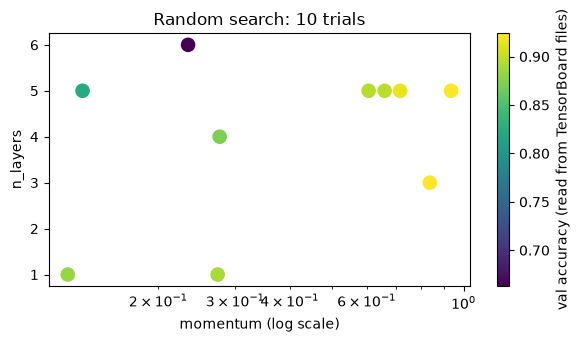

Best trial: n_layers=3.0, momentum=0.837, val_accuracy=0.9240
A Bayesian tuning service would use the first results to propose the next trials (e.g. move momentum towards the best region) instead of sampling blindly - that is why maxParallelTrials is kept small.


In [49]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sc = ax.scatter(tune_df["momentum"], tune_df["n_layers"], c=tune_df["val_accuracy"], cmap="viridis", s=90)
ax.set_xscale("log"); ax.set_xlabel("momentum (log scale)"); ax.set_ylabel("n_layers")
plt.colorbar(sc, label="val accuracy (read from TensorBoard files)"); ax.set_title("Random search: 10 trials")
plt.tight_layout(); plt.show()
best = tune_df.iloc[0]
print(f"Best trial: n_layers={best.n_layers}, momentum={best.momentum:.3f}, val_accuracy={best.val_accuracy:.4f}")
print("A Bayesian tuning service would use the first results to propose the next trials (e.g. move momentum "
      "towards the best region) instead of sampling blindly - that is why maxParallelTrials is kept small.")

In [50]:
if DOCKER_OK:
    serving.stop(quiet=True)
print("TF Serving container stopped (teardown).")

TF Serving container stopped (teardown).
